In [340]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone
import catboost
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import time
import optuna
from optuna.visualization import plot_optimization_history
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
import warnings
from optuna.exceptions import ExperimentalWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, brier_score_loss, 
precision_recall_curve, RocCurveDisplay, ConfusionMatrixDisplay, classification_report)
from sklearn.calibration import CalibrationDisplay, CalibratedClassifierCV, calibration_curve
from pathlib import Path
import shap
import json
import joblib

warnings.filterwarnings("ignore", category=ExperimentalWarning)

%matplotlib inline
RANDOM_STATE = 42

In [2]:
df_raw = pd.read_csv('credit_risk_dataset.csv')
df_raw.sample(10)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
17279,26,80000,OWN,5.0,PERSONAL,C,7000,13.22,0,0.09,Y,2
2092,21,24000,RENT,6.0,VENTURE,D,2400,16.29,0,0.10,N,3
4561,24,41100,OWN,2.0,VENTURE,B,9200,12.42,0,0.22,N,2
15123,23,122004,MORTGAGE,7.0,EDUCATION,B,11200,10.99,0,0.09,N,3
31097,39,76000,MORTGAGE,8.0,HOMEIMPROVEMENT,A,5000,6.03,0,0.07,N,14
11353,26,52800,RENT,2.0,VENTURE,D,10000,12.80,1,0.19,Y,3
16689,23,21360,RENT,0.0,MEDICAL,A,7500,7.14,1,0.35,N,4
6975,26,50648,MORTGAGE,8.0,PERSONAL,A,8000,6.76,0,0.16,N,4
6477,23,42996,RENT,2.0,EDUCATION,C,6000,12.84,0,0.14,Y,2
16973,24,138000,RENT,4.0,PERSONAL,C,5000,13.23,1,0.04,Y,4


### Dataset Overview and Data Dictionary

In [3]:
df_raw.shape

(32581, 12)

In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [5]:
df_raw.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [6]:
df_raw.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [7]:
data_dictionary = {
    'Column' : df_raw.columns,
    'Data Type' : df_raw.dtypes.astype(str).values,
    'Missing_Value' : df_raw.isna().sum().values,
    'Missing_Value_pct' : (df_raw.isna().mean().values*100).round(2),
    'n_unique' : df_raw.nunique(dropna=True).values
}
display(pd.DataFrame(data_dictionary))

,Column,Data Type,Missing_Value,Missing_Value_pct,n_unique
0,person_age,int64,0,0.00,58
1,person_income,int64,0,0.00,4295
2,person_home_ownership,str,0,0.00,4
3,person_emp_length,float64,895,2.75,36
4,loan_intent,str,0,0.00,6
5,loan_grade,str,0,0.00,7
6,loan_amnt,int64,0,0.00,753
7,loan_int_rate,float64,3116,9.56,348
8,loan_status,int64,0,0.00,2
9,loan_percent_income,float64,0,0.00,77


In [8]:
df_raw['loan_status'].unique()

array([1, 0])

### Target Definition and Class imbalance

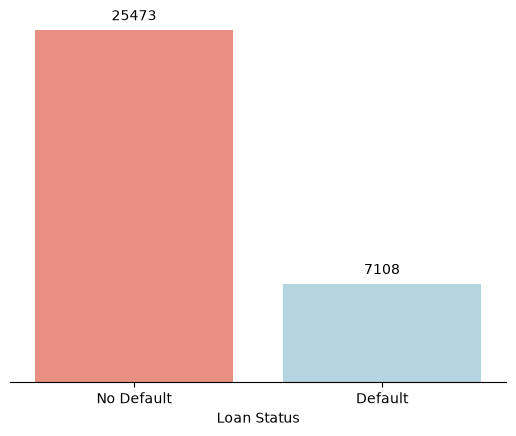

In [9]:
target_counts = df_raw['loan_status'].value_counts()
target_counts.index = ['No Default', 'Default']

bars = sns.barplot(x=target_counts.index, y = target_counts.values, palette=['salmon', 'lightblue'], hue=target_counts.index)
for container in bars.containers:
    bars.bar_label(container, padding=5)
plt.xlabel('Loan Status')
plt.ylabel('')
sns.despine(left=True)
plt.tick_params(left=False, labelleft=False)

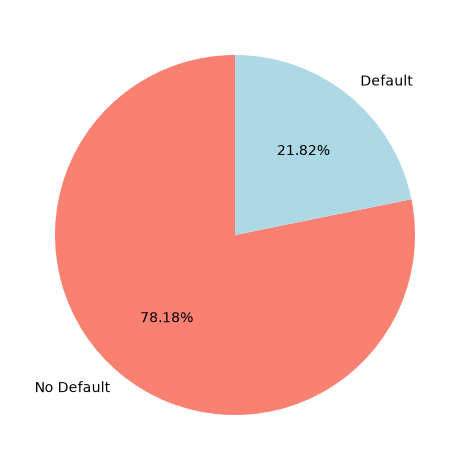

In [10]:
plt.pie(target_counts.values, labels=target_counts.index, autopct='%0.2f%%', colors = ['salmon', 'lightblue'], startangle=90)
plt.tight_layout()
plt.show()

### EDA

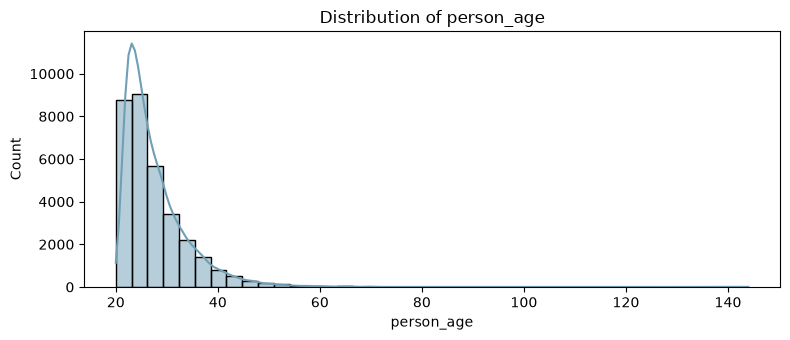

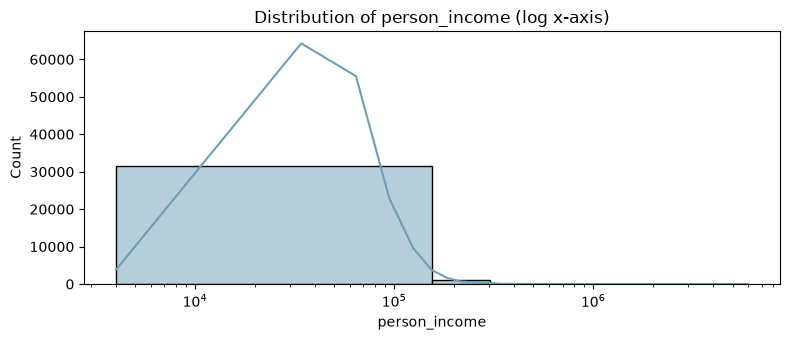

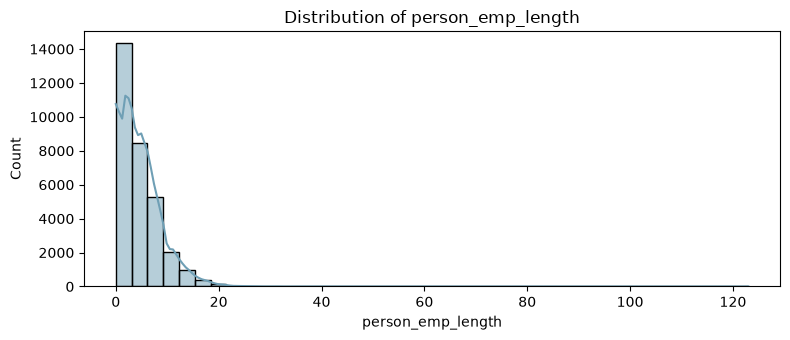

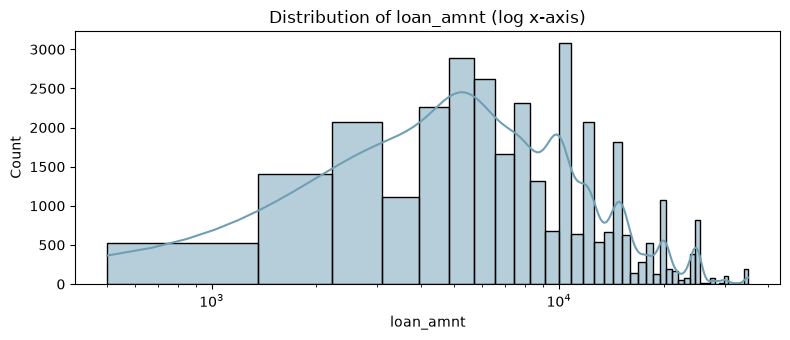

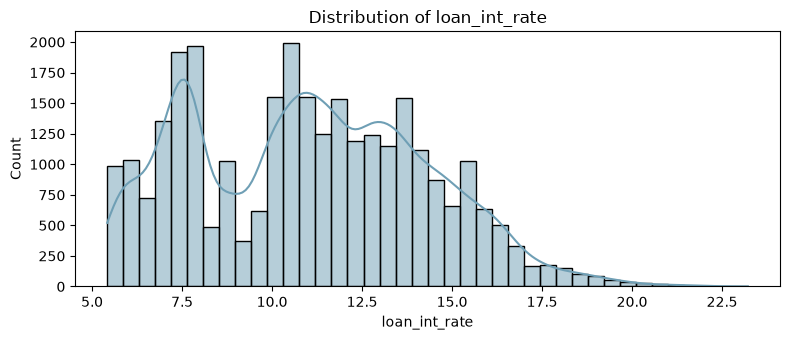

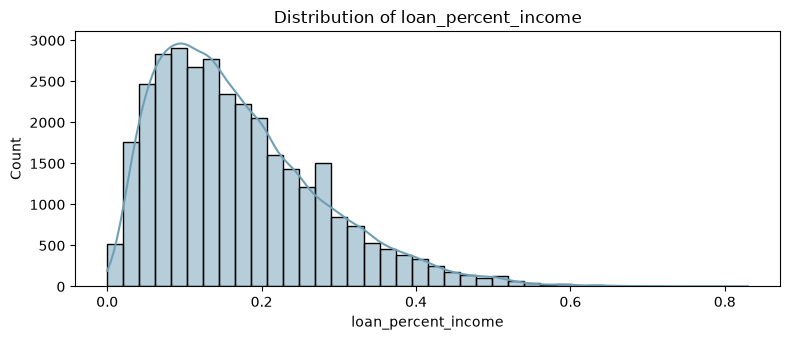

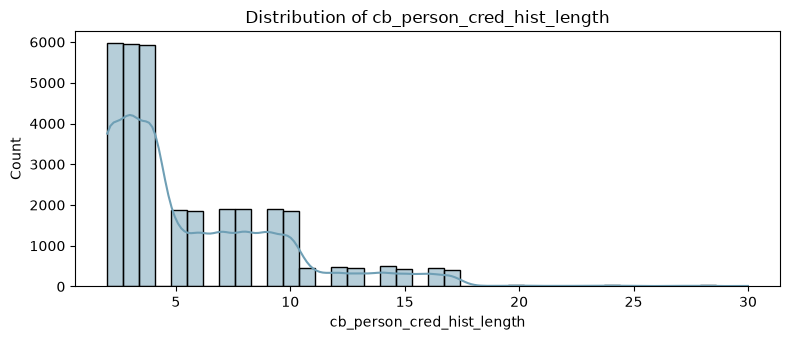

In [11]:
numeric_cols = df_raw.select_dtypes(include=np.number).columns.drop("loan_status")
categorical_cols = df_raw.select_dtypes(include='str').columns.tolist()

for col in numeric_cols:
    fig, ax = plt.subplots(figsize=(8, 3.5))
    use_log = col in ['person_income', 'loan_amnt']
    sns.histplot(df_raw[col].dropna(),bins=40, kde=True,color="#6f9fb5", ax=ax)
    if use_log and (df_raw[col].dropna() > 0).all():
        ax.set_xscale('log')
    ax.set_title(f"Distribution of {col}" + (" (log x-axis)" if use_log else ""))
    plt.tight_layout()
    plt.show()

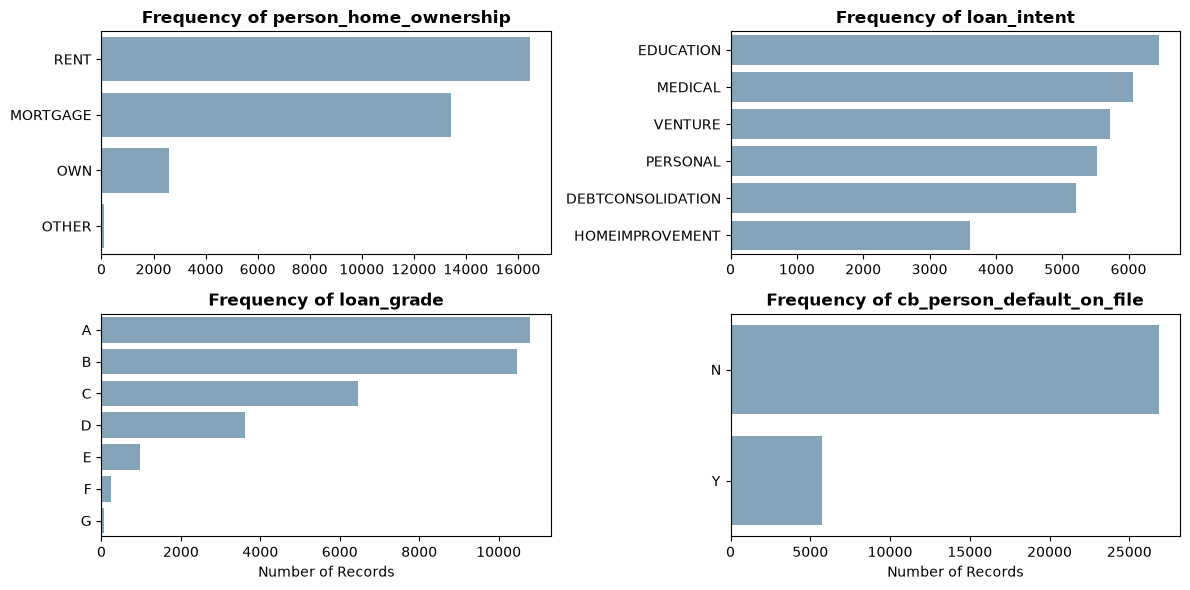

In [12]:
# Categorical Feature Frequencies
fig, axes = plt.subplots(2,2,figsize=(12, 6))
for i, (ax, col) in enumerate(zip(axes.flatten(), categorical_cols)):
    order = df_raw[col].value_counts().index
    charts = sns.countplot(data=df_raw, y=col, order=order, ax=ax, color="#7aa6c2")
    charts.set_ylabel("")
    if i == 2 or i == 3:
        charts.set_xlabel("Number of Records")
    else:
        charts.set_xlabel("")
    charts.set_title(f'Frequency of {col}', fontweight='bold')
plt.tight_layout()
plt.show()

,mean,count
loan_grade,,
G,98.44,64
F,70.54,241
E,64.42,964
D,59.05,3626
C,20.73,6458
B,16.28,10451
A,9.96,10777


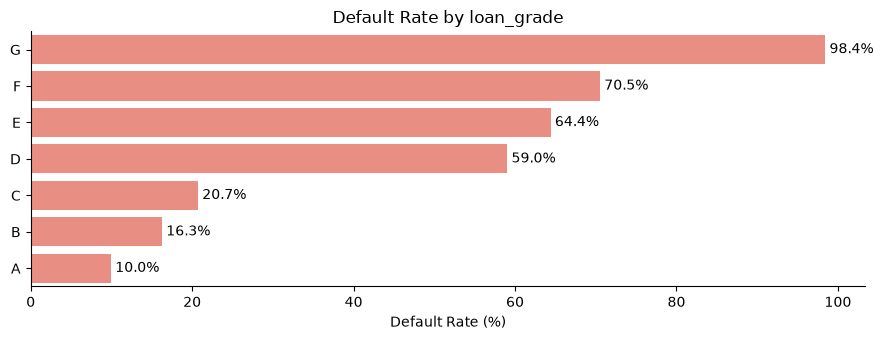

,mean,count
loan_intent,,
DEBTCONSOLIDATION,28.59,5212
MEDICAL,26.70,6071
HOMEIMPROVEMENT,26.10,3605
PERSONAL,19.89,5521
EDUCATION,17.22,6453
VENTURE,14.81,5719


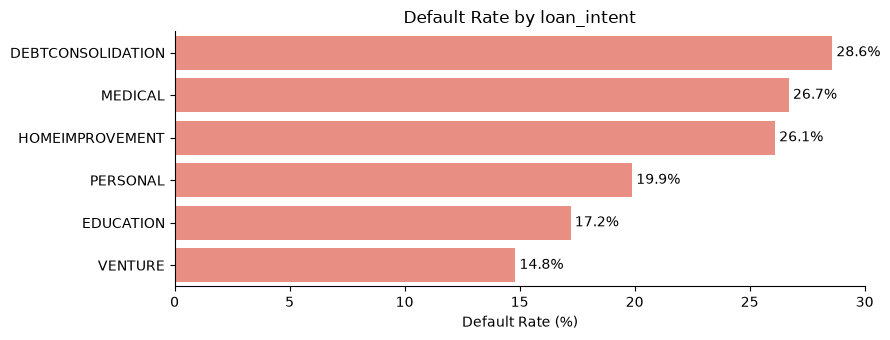

,mean,count
person_home_ownership,,
RENT,31.57,16446
OTHER,30.84,107
MORTGAGE,12.57,13444
OWN,7.47,2584


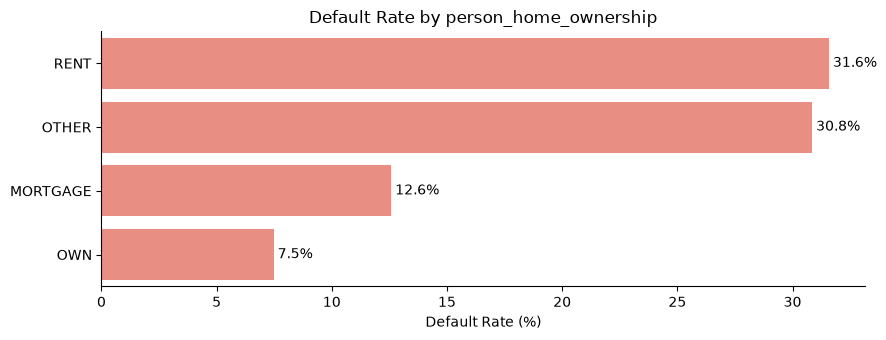

,mean,count
cb_person_default_on_file,,
Y,37.81,5745
N,18.39,26836


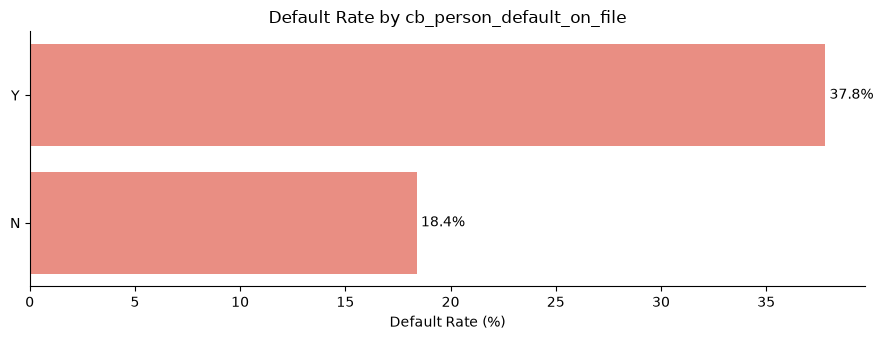

In [13]:
def plot_default_rate(data, feature):
    summary = data.groupby(feature, dropna=False, observed=True)['loan_status'].agg(['mean', 'count']).sort_values('mean', ascending=False)
    summary['mean'] *= 100
    display(summary.round(2))

    plt.figure(figsize=(9, max(3.5, len(summary)*0.42)))
    ax = sns.barplot(data=summary.reset_index(), x = 'mean', y = feature, color='salmon')
    ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)

    plt.title(f'Default Rate by {feature}')
    plt.xlabel('Default Rate (%)')
    plt.ylabel('')
    sns.despine()
    plt.tight_layout()
    plt.show()

    return summary
    

for col in ['loan_grade', 'loan_intent', 'person_home_ownership',
            'cb_person_default_on_file']:
    plot_default_rate(df_raw, col)

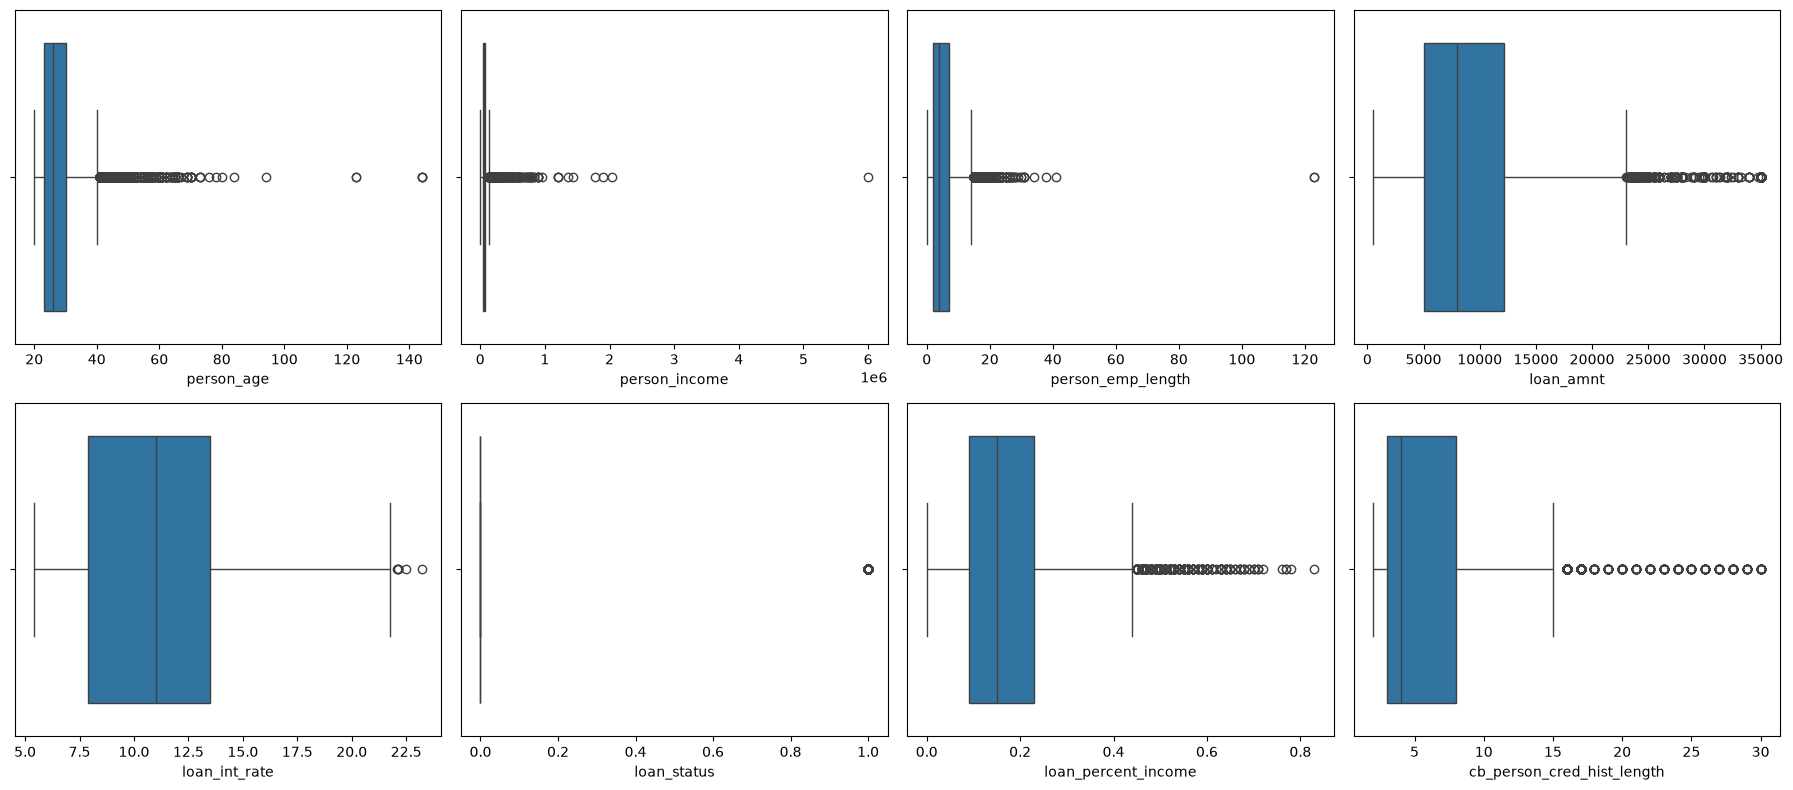

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
numerical_cols = df_raw.select_dtypes(include=np.number).columns

for ax, cols in zip(axes.flatten(), numerical_cols):
    sns.boxplot(x = df_raw[cols], ax=ax)
plt.tight_layout()
plt.show()

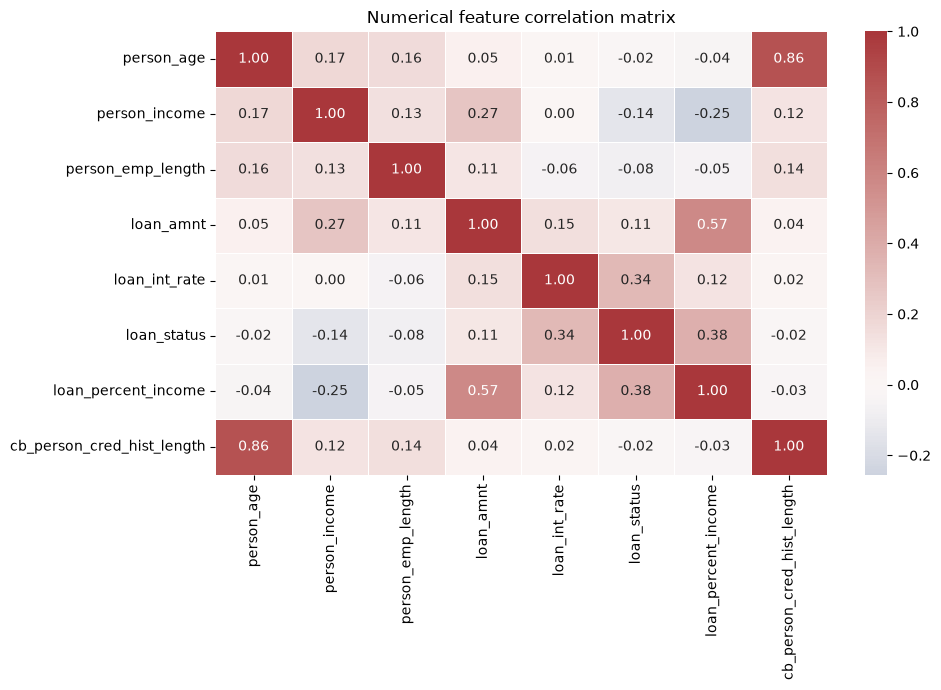

In [15]:
corr = df_raw.select_dtypes(include=np.number).corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f",
            linewidths=.5)
plt.title("Numerical feature correlation matrix")
plt.tight_layout()
plt.show()

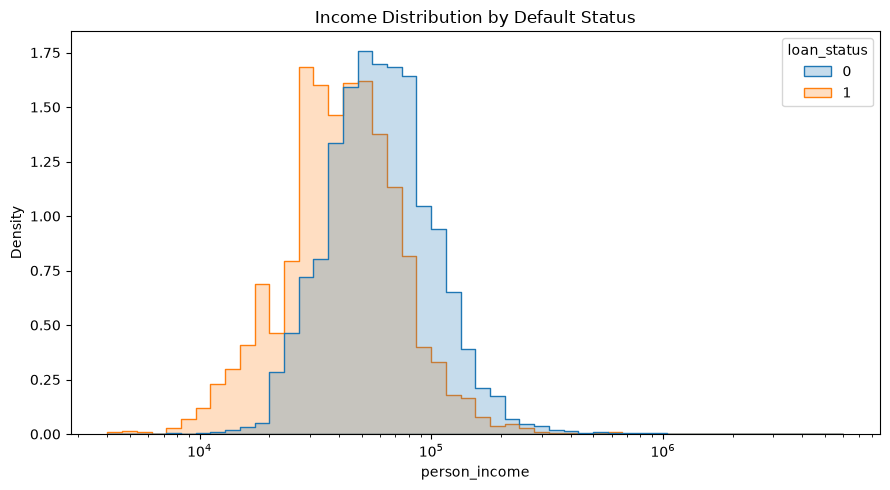

In [16]:
# Income distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df_raw,
    x='person_income',
    hue='loan_status',
    bins=50,
    log_scale=(True,False),
    element='step',
    stat='density',
    common_norm=False
)
plt.title('Income Distribution by Default Status')
plt.tight_layout()
plt.show()

,mean,count
age_group,,
56-65,25.96,104
18-25,23.03,15352
46-55,21.83,513
36-45,20.72,2814
26-35,20.68,13763
66-100,16.67,30
NaN,0.00,5


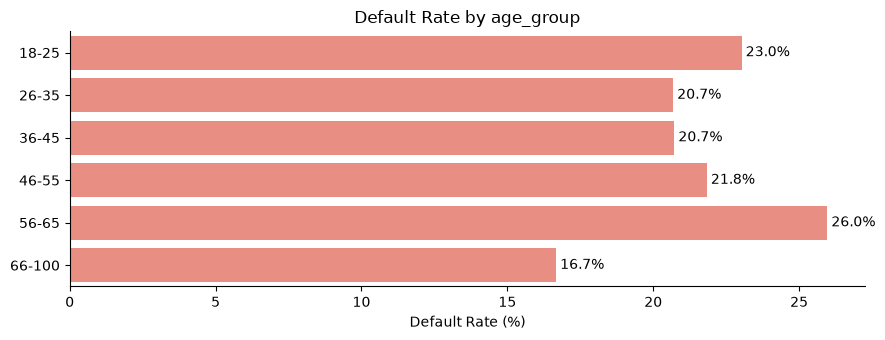

,mean,count
age_group,,
56-65,25.961538,104
18-25,23.026316,15352
46-55,21.832359,513
36-45,20.717839,2814
26-35,20.678631,13763
66-100,16.666667,30
NaN,0.000000,5


In [17]:
df_raw['age_group'] = pd.cut(df_raw['person_age'],bins=[17, 25, 35, 45, 55, 65, 100],
    labels=['18-25', '26-35', '36-45','46-55', '56-65', '66-100'])
plot_default_rate(df_raw, 'age_group')

### Data quality, duplicates and outlier investigation

In [18]:
df = df_raw.copy()

print('Rows in Original DataFrame:', len(df))
print('Number of duplicates:', df.duplicated().sum())

df = df.drop_duplicates()

print('Rows after dropping duplicates:', len(df))

df = df[
    ~(
        (df['person_age'] >= 100) |
        (df['person_age'] < 18) |
        (df['person_emp_length'] > df['person_age']) |
        (df['cb_person_cred_hist_length'] < 0) |
        (~df['loan_status'].isin([0, 1]))
    )
]

df = df[df['loan_amnt'] > 0]

print(f"Interest rate ranges between: {df['loan_int_rate'].min()}% - {df['loan_int_rate'].max()}%")
print(f'Rows after removing invalid flagged rows: ', df.shape[0])
print(f"Rows removed in total: {len(df_raw) - len(df):,}")

Rows in Original DataFrame: 32581
Number of duplicates: 165
Rows after dropping duplicates: 32416
Interest rate ranges between: 5.42% - 23.22%
Rows after removing invalid flagged rows:  32409
Rows removed in total: 172


### Features, Target and Train Test Split

In [79]:
X = df.drop(['loan_status', 'age_group'], axis=1, errors='ignore')
y = df['loan_status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

X_tune_train, X_valid, y_tune_train, y_valid = train_test_split(X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE)

post_underwriting_candidates = ["loan_grade", "loan_int_rate"]
predecision_features = [c for c in X.columns if c not in post_underwriting_candidates]

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training default rate:", round(y_train.mean(), 4))
print("Test default rate:", round(y_test.mean(), 4))
print("Potentially post-underwriting fields excluded in conservative scenario:",
      post_underwriting_candidates)

Training rows: 25927 | Test rows: 6482
Training default rate: 0.2187
Test default rate: 0.2188
Potentially post-underwriting fields excluded in conservative scenario: ['loan_grade', 'loan_int_rate']


In [80]:
def make_preprocessor(X, scale=True):
    numeric_features = X.select_dtypes(include=np.number).columns.tolist()
    categorical_features = [col for col in X.columns if col not in numeric_features]

    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        numeric_steps.append(('scale', StandardScaler()))
    numeric_pipeline = Pipeline(numeric_steps)

    categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

    return ColumnTransformer(transformers=[
        ('numeric', numeric_pipeline, numeric_features),
        ('categorical', categorical_pipeline, categorical_features)], remainder='drop', n_jobs=1)

In [81]:
model_estimators = {
    'Logistic Regression' : LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    
    'Decision Tree' : DecisionTreeClassifier(max_depth=10, min_samples_leaf=40, class_weight='balanced', random_state=RANDOM_STATE),

    'Random Forest' : RandomForestClassifier(n_estimators=500, max_features='sqrt', min_samples_leaf=5, class_weight='balanced_subsample', 
                                             n_jobs=-1, random_state=RANDOM_STATE),
    'Extra Trees' : ExtraTreesClassifier(n_estimators=500, min_samples_leaf=5, max_features='sqrt', n_jobs=-1, random_state=RANDOM_STATE,
                                        class_weight='balanced'),
    
    'HistGradientBoosting' : HistGradientBoostingClassifier(max_iter=200, max_leaf_nodes=31, min_samples_leaf=30, l2_regularization=1.0, 
                                                            learning_rate=0.08, class_weight='balanced', random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=500, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=5, reg_lambda=1.0,
        scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(), objective='binary:logistic', eval_metric='logloss', tree_method='hist',n_jobs=1,
        random_state=RANDOM_STATE, verbosity=0),
    
    'CatBoost': CatBoostClassifier(iterations=500, depth=6, learning_rate=0.05, loss_function='Logloss', eval_metric='AUC', auto_class_weights='Balanced',
        l2_leaf_reg=3.0, random_seed=RANDOM_STATE, thread_count=1, verbose=0, allow_writing_files=False)
}

In [82]:
model_pipelines = {}

for model_name, estimator in model_estimators.items():
    preprocessor = make_preprocessor(X_train, scale=(model_name == 'Logistic Regression'))
    model_pipelines[model_name] = Pipeline(steps =[
        ('preprocessor', preprocessor),
        ('model', estimator)])

In [83]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metrics = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"}

In [84]:
cv_records = []
for model_name, model in model_pipelines.items():
    print(f"Cross Validating: {model_name}")
    start = time.perf_counter()
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=metrics, n_jobs=-1, error_score = False)
    elapsed = time.perf_counter() - start
    row = {'Model_name' : model_name, 'CV_fit_time' : elapsed}
    for metric in metrics:
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std()
    cv_records.append(row)

Cross Validating: Logistic Regression
Cross Validating: Decision Tree
Cross Validating: Random Forest
Cross Validating: Extra Trees
Cross Validating: HistGradientBoosting
Cross Validating: XGBoost
Cross Validating: CatBoost


In [85]:
cv_results = pd.DataFrame(cv_records).round(4).sort_values(by='average_precision_mean', ascending=False)

In [86]:
cv_results

,Model_name,CV_fit_time,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
4,HistGradientBoosting,1.8032,0.9436,0.0021,0.8979,0.0033,0.8233,0.0126,0.7903,0.0042,0.8064,0.0062
5,XGBoost,0.4518,0.9454,0.0026,0.8975,0.0031,0.7872,0.0122,0.8014,0.0046,0.7942,0.0058
6,CatBoost,2.0171,0.9433,0.0031,0.8963,0.0044,0.8214,0.0118,0.7834,0.0049,0.8019,0.0068
2,Random Forest,3.8436,0.9288,0.0038,0.8779,0.0050,0.8791,0.0155,0.7422,0.0032,0.8048,0.0071
1,Decision Tree,0.7897,0.9140,0.0018,0.8512,0.0024,0.7184,0.0467,0.7624,0.0205,0.7382,0.0164
3,Extra Trees,2.6306,0.9012,0.0040,0.8165,0.0038,0.7110,0.0062,0.7390,0.0083,0.7247,0.0046
0,Logistic Regression,1.1019,0.8702,0.0049,0.7192,0.0119,0.5504,0.0079,0.7755,0.0047,0.6438,0.0061


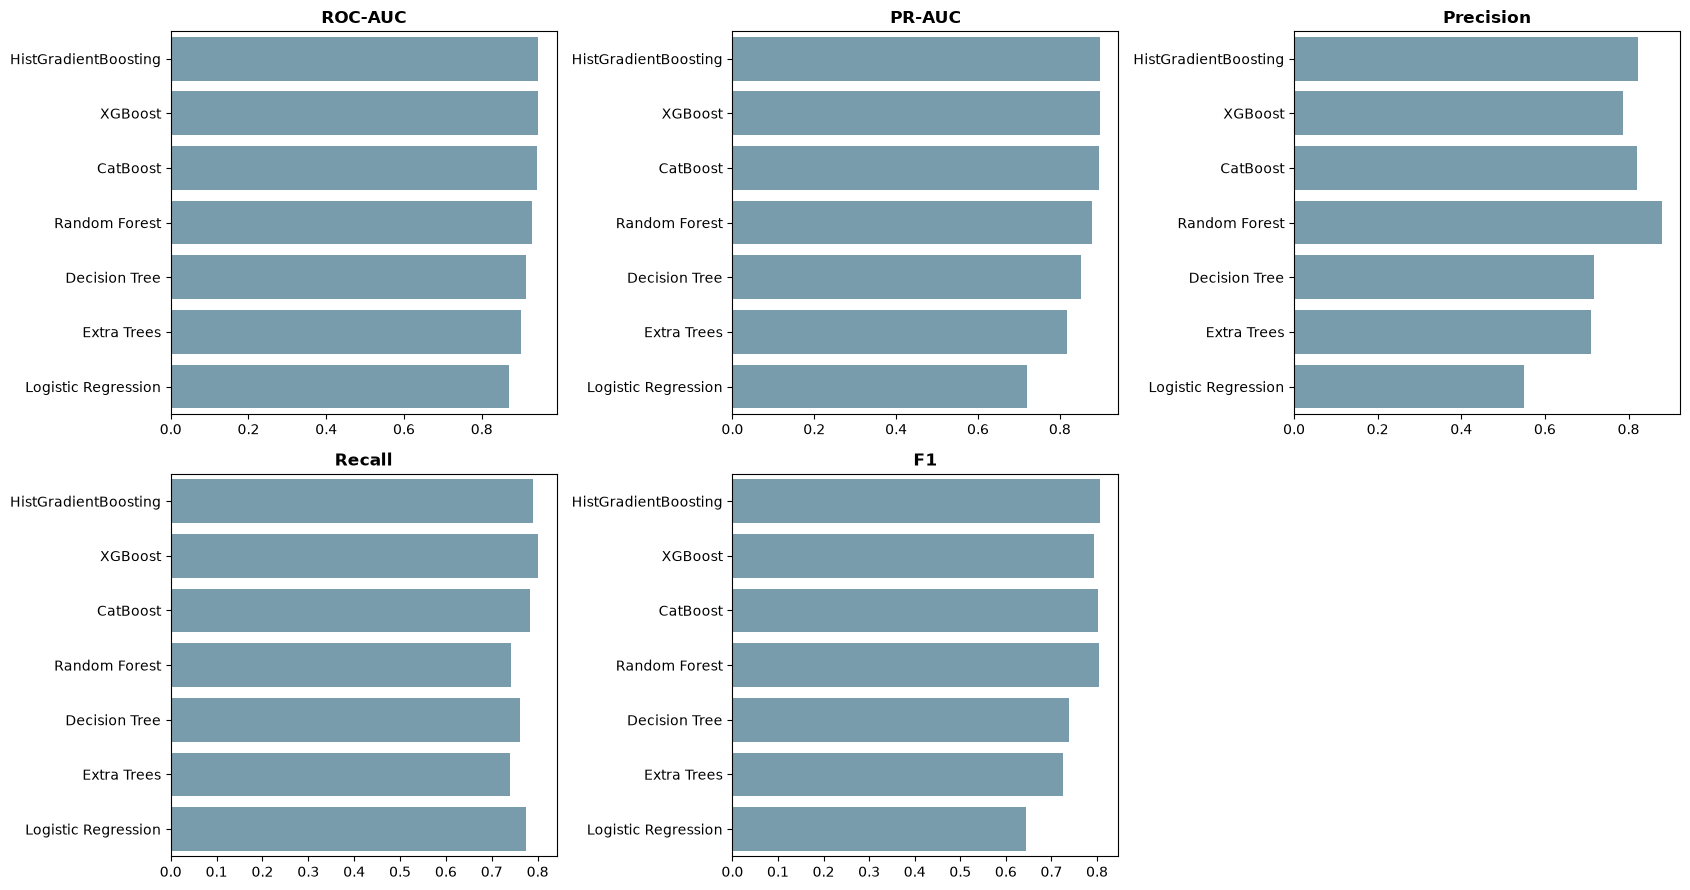

In [87]:
fig, axes = plt.subplots(2,3,figsize=(17,9))
axes = axes.flatten()
required_cols = [('roc_auc', 'ROC-AUC'), ('average_precision', 'PR-AUC'), ('precision', 'Precision'), ('recall', 'Recall'), ('f1', 'F1')]

for ax, (metric,title) in zip(axes, required_cols):
    sns.barplot(data=cv_results, x = f"{metric}_mean", y = 'Model_name', ax=ax, color="#6f9fb5")
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

### Hyperparameter Optimizing using Optuna

In [108]:
N_TRAILS = 20

TUNING_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

tuning_scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

negative_count = int((y_tune_train == 0).sum())
positive_count = int((y_tune_train == 1).sum())
base_pos_weight =  negative_count / positive_count

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print("Positive class weight:", base_pos_weight)

Negative samples: 17218
Positive samples: 4819
Positive class weight: 3.572940444075534


In [109]:
def suggest_model_params(trial, model_name):
    if model_name == 'Logistic Regression':
        return {"C" : trial.suggest_float('C', 1e-3, 100, log=True),
                "class_weight" : trial.suggest_categorical('class_weight', [None, 'balanced'])}

    if model_name == 'Decision Tree':
        return {'max_depth' : trial.suggest_int('max_depth',3 , 30),
                'min_samples_split' : trial.suggest_int('min_samples_split', 2, 40),
                'min_samples_leaf' : trial.suggest_int('min_samples_leaf', 2, 40),            
                "max_features": trial.suggest_categorical("max_features", [None, "sqrt", "log2"]),
                "class_weight": trial.suggest_categorical(
                "class_weight", [None, "balanced"])}

    if model_name in ["Random Forest", "Extra Trees"]:
        return {
            "n_estimators": trial.suggest_int(
                "n_estimators", 200, 600, step=100
            ),
            "max_depth": trial.suggest_categorical(
                "max_depth", [None, 10, 16, 24, 32]
            ),
            "min_samples_split": trial.suggest_int(
                "min_samples_split", 2, 20
            ),
            "min_samples_leaf": trial.suggest_int(
                "min_samples_leaf", 1, 10
            ),
            "max_features": trial.suggest_categorical(
                "max_features", ["sqrt", "log2", 0.5, 0.8]
            ),
            "class_weight": trial.suggest_categorical(
                "class_weight",
                [None, "balanced"] if model_name == "Extra Trees"
                else [None, "balanced", "balanced_subsample"]
            )
        }

    if model_name == "HistGradientBoosting":
        return {
            "max_iter": trial.suggest_int("max_iter", 100, 400, step=50),
            "learning_rate": trial.suggest_float(
                "learning_rate", 0.02, 0.20, log=True
            ),
            "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 15, 63),
            "min_samples_leaf": trial.suggest_int(
                "min_samples_leaf", 10, 60
            ),
            "l2_regularization": trial.suggest_float(
                "l2_regularization", 1e-6, 10.0, log=True
            ),
            "class_weight": trial.suggest_categorical(
                "class_weight", [None, "balanced"]
            )
        }

    if model_name == "XGBoost":
        pos_weight_multiplier = trial.suggest_float(
            "pos_weight_multiplier", 0.75, 1.50
        )
        return {
            "n_estimators": trial.suggest_int(
                "n_estimators", 200, 700, step=100
            ),
            "max_depth": trial.suggest_int("max_depth", 3, 8),
            "learning_rate": trial.suggest_float(
                "learning_rate", 0.01, 0.15, log=True
            ),
            "subsample": trial.suggest_float("subsample", 0.70, 1.0),
            "colsample_bytree": trial.suggest_float(
                "colsample_bytree", 0.70, 1.0
            ),
            "min_child_weight": trial.suggest_float(
                "min_child_weight", 1.0, 10.0
            ),
            "gamma": trial.suggest_float("gamma", 0.0, 5.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 5.0),
            "reg_lambda": trial.suggest_float(
                "reg_lambda", 0.1, 20.0, log=True
            ),
            "scale_pos_weight": base_pos_weight * pos_weight_multiplier
        }

    if model_name == "CatBoost":
        return {
            "iterations": trial.suggest_int(
                "iterations", 300, 800, step=100
            ),
            "depth": trial.suggest_int("depth", 4, 8),
            "learning_rate": trial.suggest_float(
                "learning_rate", 0.02, 0.15, log=True
            ),
            "l2_leaf_reg": trial.suggest_float(
                "l2_leaf_reg", 1.0, 10.0, log=True
            ),
            "random_strength": trial.suggest_float(
                "random_strength", 0.0, 2.0
            ),
            "auto_class_weights": trial.suggest_categorical(
                "auto_class_weights", [None, "Balanced", "SqrtBalanced"]
            )
        }

    raise ValueError(f"Unknown model: {model_name}")        

In [110]:
def make_estimators(model_name, params):
    if model_name == 'Logistic Regression':
        return LogisticRegression(**params, max_iter=3000, random_state=RANDOM_STATE)

    if model_name == "Decision Tree":
        return DecisionTreeClassifier(
            **params, random_state=RANDOM_STATE
        )

    if model_name == "Random Forest":
        return RandomForestClassifier(
            **params, n_jobs=-1, random_state=RANDOM_STATE
        )

    if model_name == "Extra Trees":
        return ExtraTreesClassifier(
            **params, n_jobs=-1, random_state=RANDOM_STATE
        )

    if model_name == "HistGradientBoosting":
        return HistGradientBoostingClassifier(
            **params, random_state=RANDOM_STATE
        )

    if model_name == "XGBoost":
        return XGBClassifier(
            **params,
            objective="binary:logistic",
            eval_metric="aucpr",
            tree_method="hist",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )

    if model_name == "CatBoost":
        return CatBoostClassifier(
            **params,
            loss_function="Logloss",
            eval_metric="AUC",
            thread_count=1,
            random_seed=RANDOM_STATE,
            verbose=False,
            allow_writing_files=False
        )

    raise ValueError(f"Unknown model: {model_name}")

In [111]:
def make_model_pipeline(model_name, params):
    estimator = make_estimators(model_name, params)
    preprocessor = make_preprocessor(X_tune_train, scale = (model_name == 'Logistic Regression'))
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

In [112]:
def objective(trial, model_name):
    params = suggest_model_params(trial, model_name)
    pipeline = make_model_pipeline(model_name, params)

    fold_scores = cross_validate(pipeline, 
                                 X_tune_train, 
                                 y_tune_train, 
                                 cv = TUNING_CV,
                                 scoring = tuning_scoring,
                                 n_jobs=-1,
                                 error_score='raise'
                                )
    for metric in tuning_scoring:
        metric_values = fold_scores[f"test_{metric}"]
        trial.set_user_attr(f"{metric}_mean", float(metric_values.mean()))
        trial.set_user_attr(f"{metric}_std", float(metric_values.std()))

    trial.set_user_attr('mean_fit_time_sec', float(np.mean(fold_scores['fit_time'])))
    return float(fold_scores["test_average_precision"].mean())

In [113]:
model_names = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "Extra Trees",
    "HistGradientBoosting",
    "XGBoost",
    "CatBoost"
]

studies = {}
study_time = {}

for model_name in model_names:
    print(f"\n Optimizing {model_name} ({N_TRAILS} trials...)")
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(), study_name=model_name.replace(' ', '_'))
    start_time = time.perf_counter()
    study.optimize(lambda trial, name = model_name : objective(trial, name), n_trials=N_TRAILS, show_progress_bar=True)
    study_time[model_name] = time.perf_counter() - start_time
    studies[model_name] = study
    print(f"Best CV Average Precision: {study.best_value:.4f}")
    print(f"Best CV Average Precision: {study.best_params}")

[I 2026-11-03 10:26:45,994] A new study created in memory with name: Logistic_Regression



 Optimizing Logistic Regression (20 trials...)


Best trial: 0. Best value: 0.730583:   5%|█▍                          | 1/20 [00:01<00:23,  1.24s/it]

[I 2026-11-03 10:26:47,238] Trial 0 finished with value: 0.7305827444786022 and parameters: {'C': 0.9550368263657252, 'class_weight': None}. Best is trial 0 with value: 0.7305827444786022.


Best trial: 1. Best value: 0.730862:  10%|██▊                         | 2/20 [00:01<00:16,  1.07it/s]

[I 2026-11-03 10:26:47,954] Trial 1 finished with value: 0.7308619783333152 and parameters: {'C': 33.463764077254616, 'class_weight': None}. Best is trial 1 with value: 0.7308619783333152.


... (240 outputs left out)

Best trial: 18. Best value: 0.902159:  95%|████████████████████████▋ | 19/20 [00:43<00:01,  1.77s/it]

[I 2026-11-03 10:30:53,891] Trial 18 finished with value: 0.9021588255572393 and parameters: {'iterations': 400, 'depth': 4, 'learning_rate': 0.1494341134373838, 'l2_leaf_reg': 1.9616570670410416, 'random_strength': 1.2810987228114339, 'auto_class_weights': None}. Best is trial 18 with value: 0.9021588255572393.


Best trial: 18. Best value: 0.902159: 100%|██████████████████████████| 20/20 [00:45<00:00,  2.26s/it]

[I 2026-11-03 10:30:55,704] Trial 19 finished with value: 0.9015061034465457 and parameters: {'iterations': 500, 'depth': 4, 'learning_rate': 0.1241456409430627, 'l2_leaf_reg': 1.547984560314623, 'random_strength': 1.0495058848059142, 'auto_class_weights': None}. Best is trial 18 with value: 0.9021588255572393.
Best CV Average Precision: 0.9022
Best CV Average Precision: {'iterations': 400, 'depth': 4, 'learning_rate': 0.1494341134373838, 'l2_leaf_reg': 1.9616570670410416, 'random_strength': 1.2810987228114339, 'auto_class_weights': None}


In [114]:
model_estimators = {}
model_pipelines = {}
cv_records = []

for model_name, study in studies.items():
    best_params = study.best_params.copy()
    if model_name == 'XGBoost':
        multiplier = best_params.pop('pos_weight_multiplier')
        best_params['scale_pos_weight'] = base_pos_weight * multiplier
    estimators = make_estimators(model_name, best_params)
    model_estimators[model_name] = estimators

    preprocessor = make_preprocessor(X_tune_train, scale=(model_name == 'Logistic Regression'))
    model_pipelines[model_name] = Pipeline(steps = [
        ('preprocessor', preprocessor),
        ('model', estimators)])

    best_trial = study.best_trial
    row = {'Model' : model_name,
           'Best Trial' : best_trial.number,
           'Trials Completed' : len(study.trials),
           'Optuna Search Time' : study_time[model_name],
           'Mean Fold Time' : best_trial.user_attrs['mean_fit_time_sec']}

    for metric in tuning_scoring:
        row[f"{metric}_mean"] = best_trial.user_attrs[f"{metric}_mean"]
        row[f"{metric}_std"] = best_trial.user_attrs[f"{metric}_std"]
    cv_records.append(row)

In [117]:
cv_results = pd.DataFrame(cv_records).sort_values(
    "average_precision_mean", ascending=False
).reset_index(drop=True)

cv_display = cv_results[[
    "Model", "roc_auc_mean", "average_precision_mean",
    "precision_mean", "recall_mean", "f1_mean",
    "Optuna Search Time"
]].rename(columns={
    "roc_auc_mean": "CV ROC-AUC",
    "average_precision_mean": "CV Average Precision",
    "precision_mean": "CV Precision",
    "recall_mean": "CV Recall",
    "f1_mean": "CV F1"
})
display(cv_display.round(4))

best_model_name = cv_results.loc[0, "Model"]
best_study = studies[best_model_name]
print(f"\nSelected model by best CV Average Precision: {best_model_name}")
print("Selected hyperparameters:", best_study.best_params)

,Model,CV ROC-AUC,CV Average Precision,CV Precision,CV Recall,CV F1,Optuna Search Time
0,CatBoost,0.9448,0.9022,0.9663,0.7371,0.8362,45.2130
1,XGBoost,0.9462,0.9014,0.7971,0.8072,0.8021,11.1442
2,HistGradientBoosting,0.9432,0.8979,0.9578,0.7246,0.8250,20.2241
3,Random Forest,0.9353,0.8884,0.9534,0.7223,0.8219,99.9454
4,Extra Trees,0.9243,0.8742,0.9733,0.7039,0.8169,66.7177
5,Decision Tree,0.9112,0.8556,0.6963,0.7819,0.7365,1.7899
6,Logistic Regression,0.8702,0.7309,0.7694,0.5611,0.6489,4.6720



Selected model by best CV Average Precision: CatBoost
Selected hyperparameters: {'iterations': 400, 'depth': 4, 'learning_rate': 0.1494341134373838, 'l2_leaf_reg': 1.9616570670410416, 'random_strength': 1.2810987228114339, 'auto_class_weights': None}


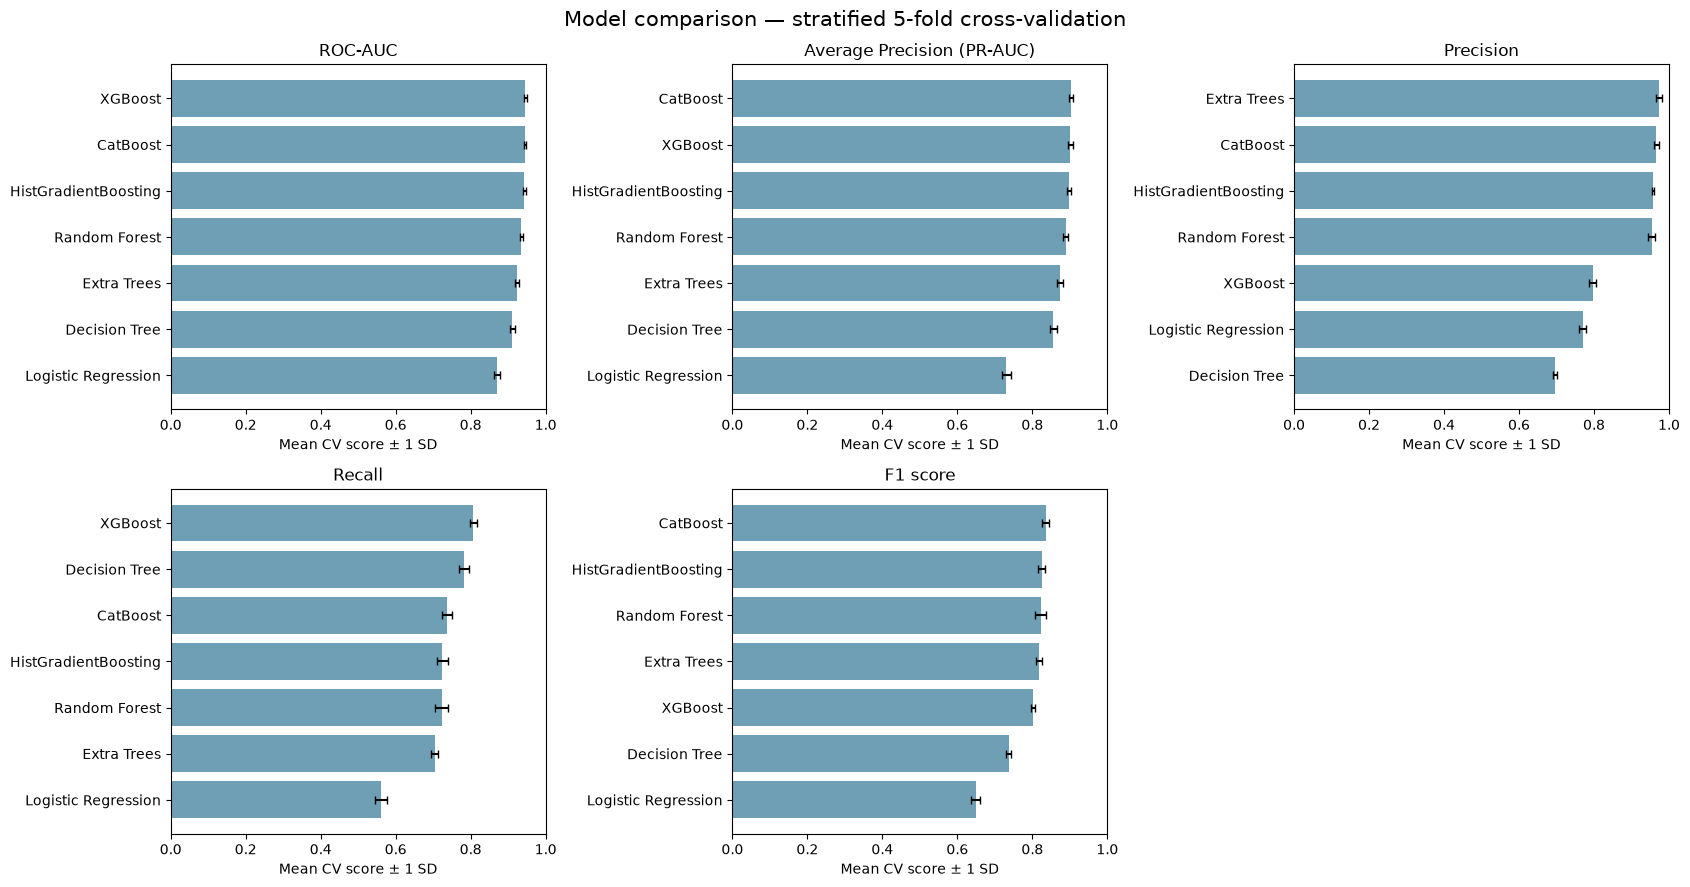

In [120]:
metric_config = [
    ("roc_auc", "ROC-AUC"),
    ("average_precision", "Average Precision (PR-AUC)"),
    ("precision", "Precision"),
    ("recall", "Recall"),
    ("f1", "F1 score")
]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (metric, title) in zip(axes.flat, metric_config):
    plot_data = cv_results.sort_values(f"{metric}_mean", ascending=True)
    ax.barh(
        plot_data["Model"], plot_data[f"{metric}_mean"],
        xerr=plot_data[f"{metric}_std"], capsize=3, color="#6f9fb5"
    )
    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Mean CV score ± 1 SD")

axes.flat[-1].axis("off")
fig.suptitle("Model comparison — stratified 5-fold cross-validation", fontsize=15)
plt.tight_layout()
plt.show()

Optimization History: Logistic Regression


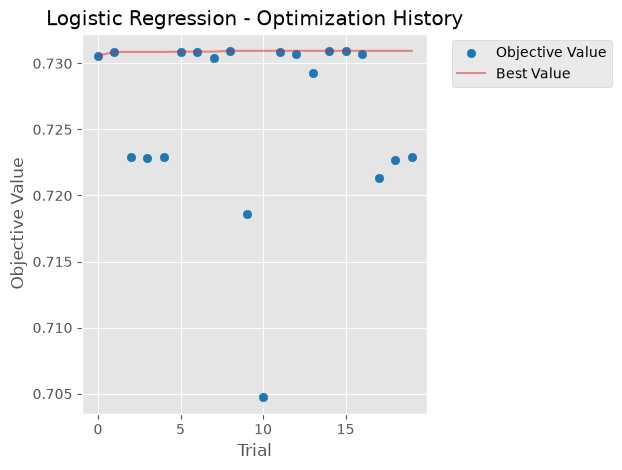

Optimization History: Decision Tree


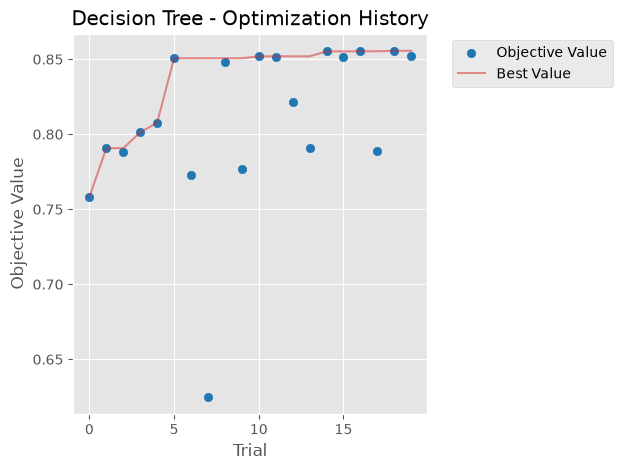

Optimization History: Random Forest


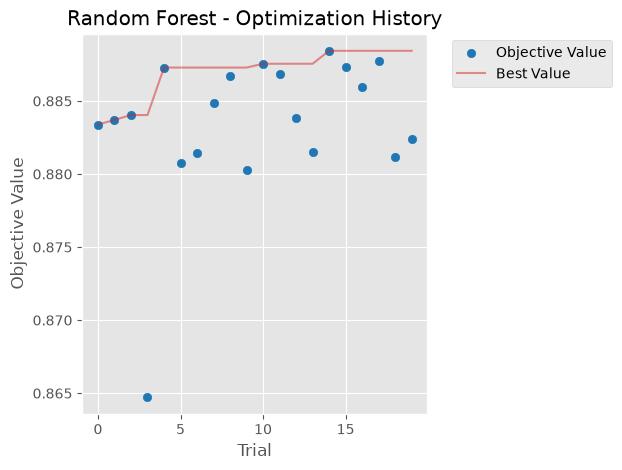

Optimization History: Extra Trees


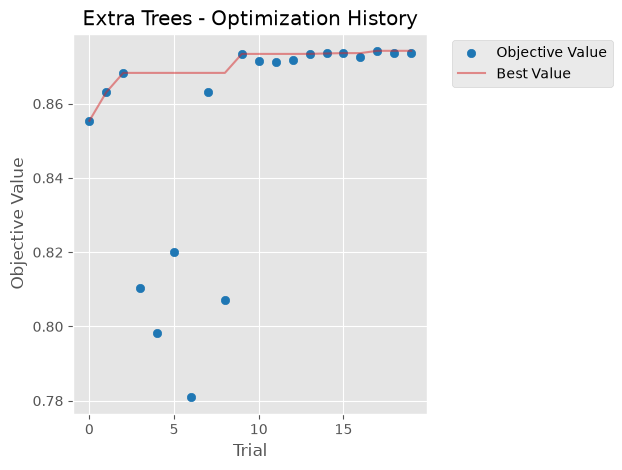

Optimization History: HistGradientBoosting


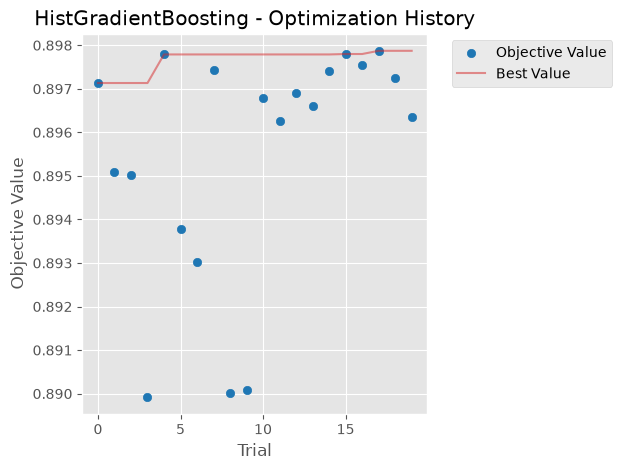

Optimization History: XGBoost


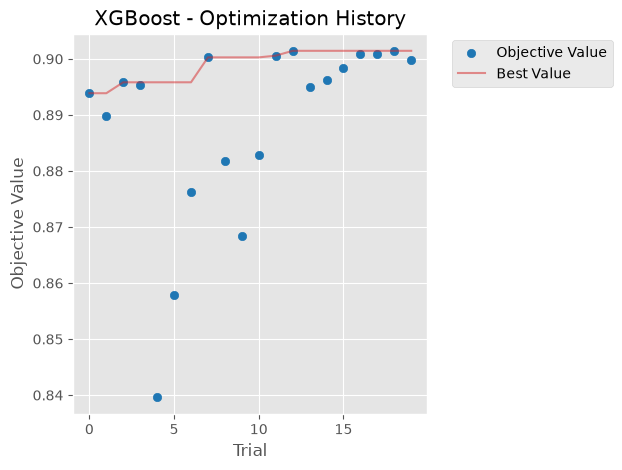

Optimization History: CatBoost


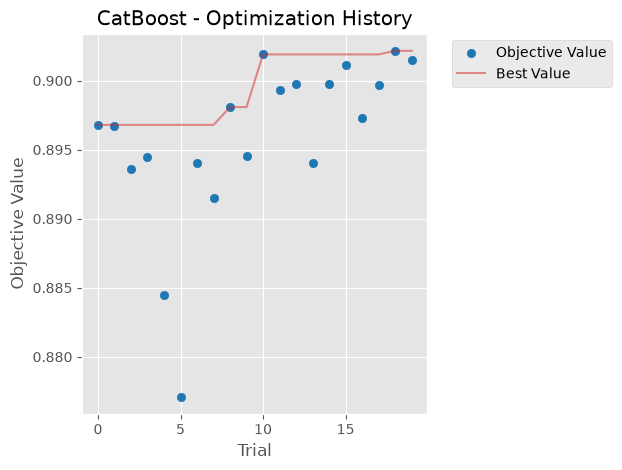

In [161]:
for model_name, study in studies.items():

    print(f"Optimization History: {model_name}")

    ax = plot_optimization_history(study)

    ax.set_title(f"{model_name} - Optimization History")

    plt.show()

Hyperparameter Importance: Logistic Regression


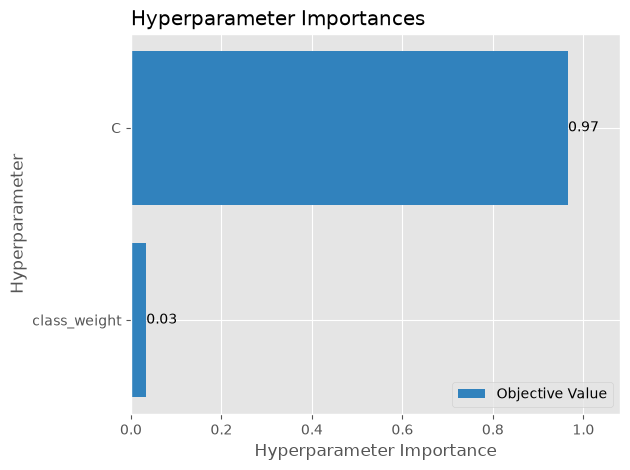

Hyperparameter Importance: Decision Tree


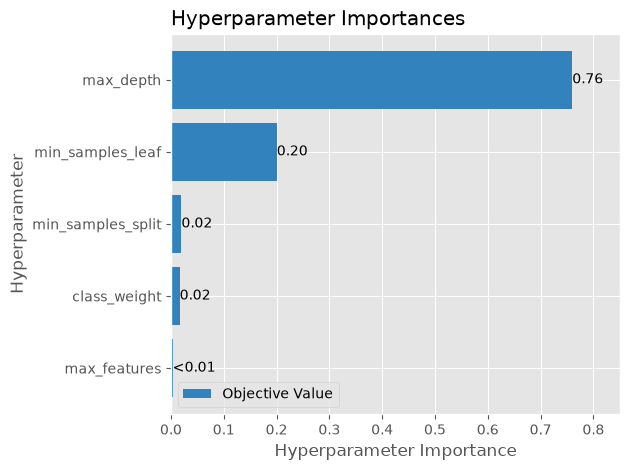

Hyperparameter Importance: Random Forest


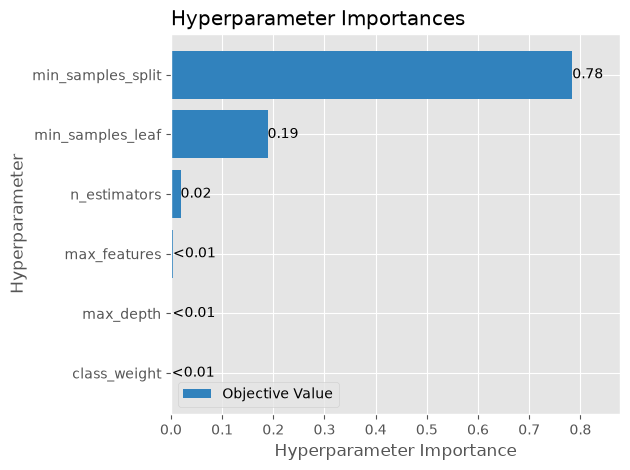

Hyperparameter Importance: Extra Trees


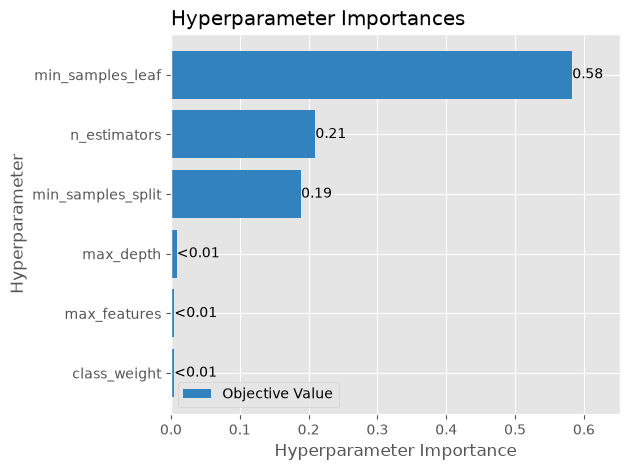

Hyperparameter Importance: HistGradientBoosting


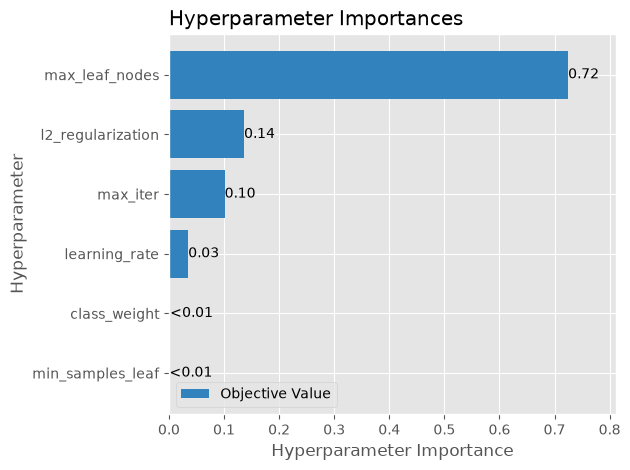

Hyperparameter Importance: XGBoost


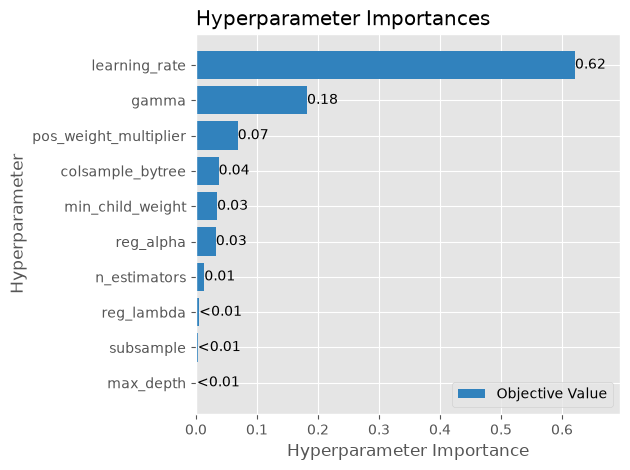

Hyperparameter Importance: CatBoost


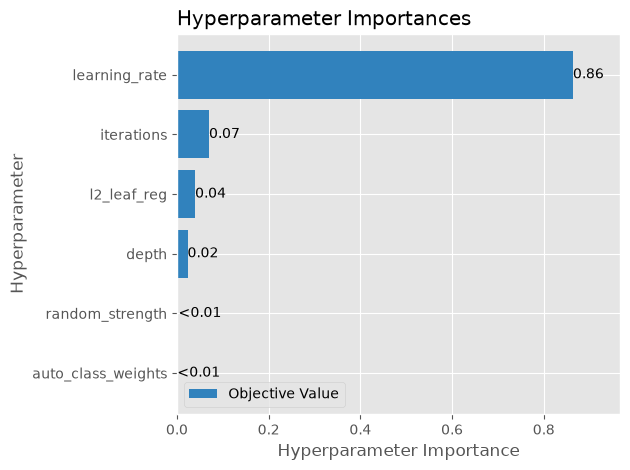

In [163]:
for model_name, study in studies.items():

    print(f"Hyperparameter Importance: {model_name}")

    ax = plot_param_importances(study)

    # ax.set_title(f"{model_name} - Hyperparameter Importance")
    plt.tight_layout()
    plt.show()

# Fit the tuned candidates and compare held-out test performance

In [173]:
fitted_models = {}
y_pred_probabilities = {}
y_pred_dict = {}

for model_name, pipeline in model_pipelines.items():
    fitted = clone(pipeline)
    fitted.fit(X_train, y_train)
    fitted_models[model_name] = fitted
    probabilities = fitted.predict_proba(X_test)[:,1]
    y_pred_probabilities[model_name] = probabilities
    y_pred_dict[model_name] = (probabilities > 0.5).astype(int)

def calculate_metrics(y_true, y_pred, y_probability):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_probability),
        "Average Precision": average_precision_score(y_true, y_probability),
        "Brier score": brier_score_loss(y_true, y_probability)
    }

test_metric_rows = []

for model_name in model_pipelines:
    row = {'Model' : model_name, 'Threshold' : 0.5}
    row.update(calculate_metrics(y_test, y_pred_dict[model_name], y_pred_probabilities[model_name]))
    test_metric_rows.append(row)
    
test_results = pd.DataFrame(test_metric_rows).sort_values(
    "Average Precision", ascending=False
).reset_index(drop=True)
display(test_results.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier score
0,XGBoost,0.5,0.9099,0.7733,0.8322,0.8016,0.9529,0.9127,0.0671
1,CatBoost,0.5,0.9398,0.9733,0.7454,0.8442,0.9492,0.9092,0.0495
2,HistGradientBoosting,0.5,0.9374,0.9659,0.7398,0.8379,0.9480,0.9069,0.0512
3,Random Forest,0.5,0.9347,0.9585,0.7334,0.8310,0.9432,0.9017,0.0542
4,Extra Trees,0.5,0.9351,0.9835,0.7151,0.8281,0.9286,0.8813,0.0577
5,Decision Tree,0.5,0.8706,0.6735,0.7927,0.7282,0.9176,0.8660,0.0882
6,Logistic Regression,0.5,0.8650,0.7593,0.5606,0.6450,0.8702,0.7187,0.1030


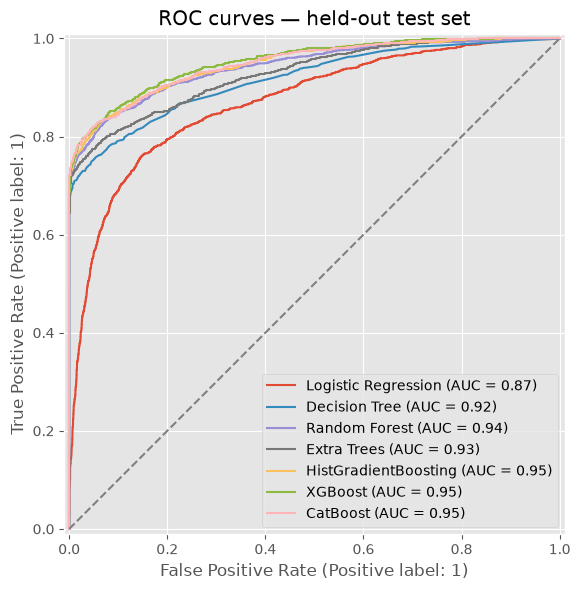

In [180]:
fig, ax = plt.subplots(figsize=(12,6))
for model_name, probabilities in y_pred_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, y_pred_probabilities[model_name], name=model_name, ax = ax)

ax.plot([0,1], [0,1], linestyle="--", color="grey", label="Random classifier")
ax.set_title("ROC curves — held-out test set")
plt.tight_layout()
plt.show()

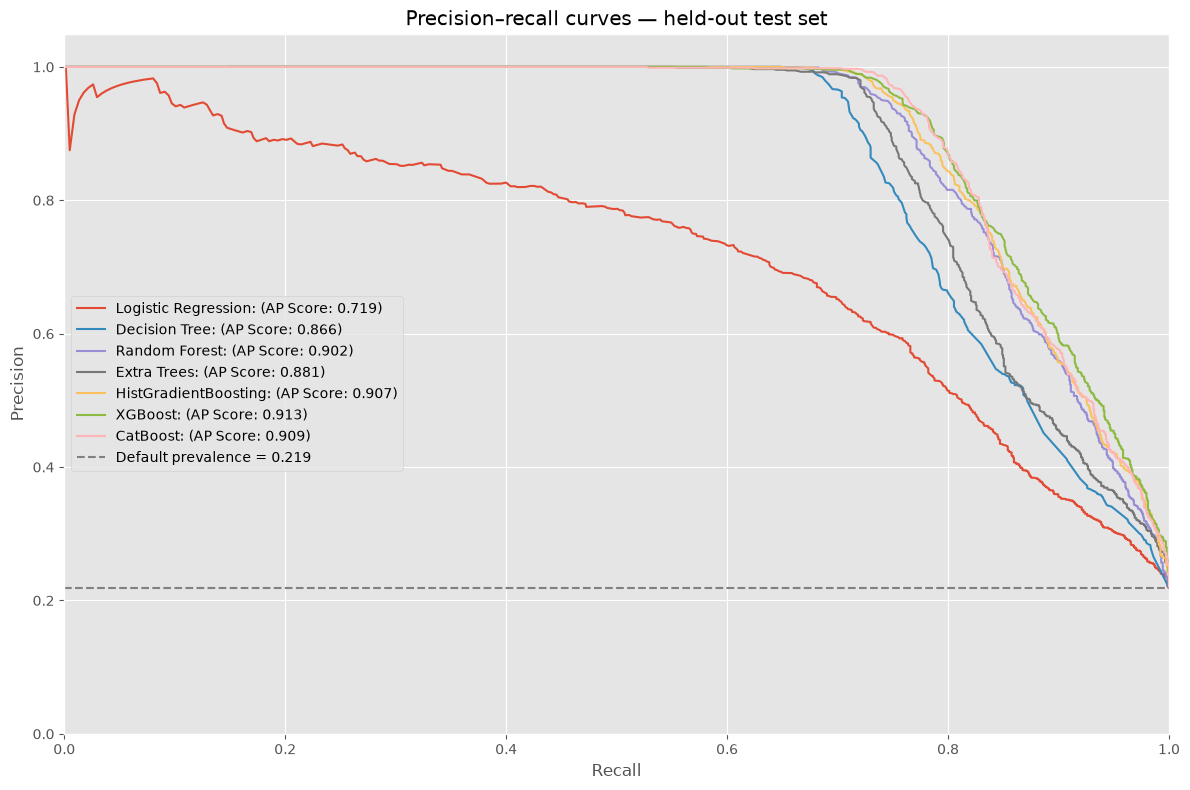

In [209]:
fig, ax = plt.subplots(figsize=(12,8))

for model_name, probabilities in y_pred_probabilities.items():
    precision, recall , threshold = precision_recall_curve(y_test, probabilities)
    display_step = max(1, len(recall) // 1000)
    ap_score = average_precision_score(y_test, probabilities)
    ax.plot(recall[::display_step], precision[::display_step], label=f"{model_name}: (AP Score: {ap_score:.3f})")
    ax.set(xlabel='Recall', ylabel='Precision', xlim=(0,1), ylim=(0,1.05), title="Precision–recall curves — held-out test set")

ax.axhline(y_test.mean(), linestyle='--', color='grey', label=f"Default prevalence = {y_test.mean():.3f}")
plt.legend()
plt.tight_layout()
plt.show()


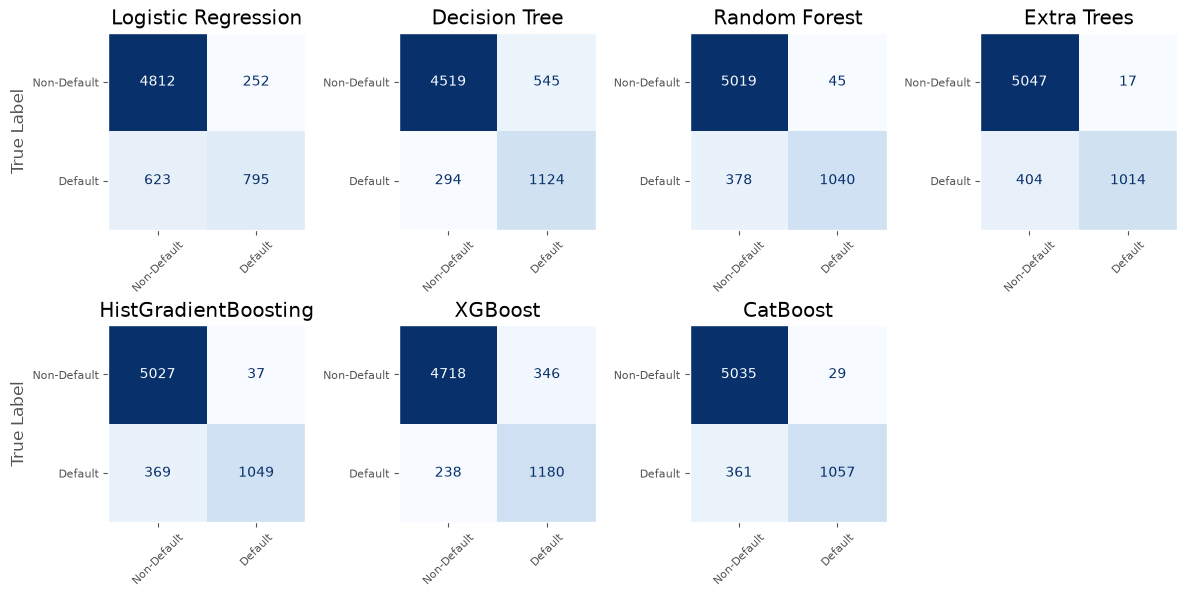

In [234]:
fig, axes = plt.subplots(2, 4, figsize=(12,6))
axes = axes.flatten()

for i ,  (ax, (model_name, predictions)) in enumerate(zip(axes, y_pred_dict.items())):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, ax=ax, colorbar=False, cmap='Blues', display_labels = ['Non-Default', 'Default'])
    ax.grid(False)
    ax.tick_params(axis='x', labelrotation=45, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)
    ax.set_title(f"{model_name}")
    if i == 0 or i == 4:
        ax.set_ylabel('True Label')
    else:
        ax.set_ylabel("")
    ax.set_xlabel("")

fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

In [267]:
candidate_names = cv_results.head(3)['Model'].tolist()

for model_name in candidate_names:
    threshold_model = clone(model_pipelines[model_name])
    threshold_model.fit(X_tune_train, y_tune_train)
    valid_probabilites = threshold_model.predict_proba(X_valid)[:,1]
    
    valid_precision, valid_recall, valid_threshold = precision_recall_curve(y_valid, valid_probabilites)
    
    valid_f1 = (2 * (valid_precision[:-1] * valid_recall[:-1])) / (valid_precision[:-1] + valid_recall[:-1] + 1e-12)
    best_threshold_index = np.nanargmax(valid_f1)
    best_threshold = valid_threshold[best_threshold_index]
    
    print(f"Selected model: {model_name}")
    print(f"Validation-selected threshold: {best_threshold:.3f}")
    print(f"Validation precision: {valid_precision[best_threshold_index]:.3f}")
    print(f"Validation recall: {valid_recall[best_threshold_index]:.3f}")
    print(f"Validation F1: {valid_f1[best_threshold_index]:.3f}")
    print()

Selected model: CatBoost
Validation-selected threshold: 0.259
Validation precision: 0.886
Validation recall: 0.756
Validation F1: 0.815

Selected model: XGBoost
Validation-selected threshold: 0.676
Validation precision: 0.923
Validation recall: 0.727
Validation F1: 0.813

Selected model: HistGradientBoosting
Validation-selected threshold: 0.395
Validation precision: 0.927
Validation recall: 0.712
Validation F1: 0.805



In [272]:
best_model_name = cv_results.loc[0, 'Model']

threshold_model = clone(model_pipelines[best_model_name])
threshold_model.fit(X_tune_train, y_tune_train)

valid_probabilities = threshold_model.predict_proba(X_valid)[:, 1]

valid_precision, valid_recall, valid_threshold = precision_recall_curve(
    y_valid, valid_probabilities
)

valid_f1 = (
    2 * valid_precision[:-1] * valid_recall[:-1]
) / (
    valid_precision[:-1] + valid_recall[:-1] + 1e-12
)

best_threshold_index = np.nanargmax(valid_f1)
best_threshold = valid_threshold[best_threshold_index]

print(f"Selected model: {best_model_name}")
print(f"Validation-selected threshold: {best_threshold:.3f}")
print(f"Validation precision: {valid_precision[best_threshold_index]:.3f}")
print(f"Validation recall: {valid_recall[best_threshold_index]:.3f}")
print(f"Validation F1: {valid_f1[best_threshold_index]:.3f}")

Selected model: CatBoost
Validation-selected threshold: 0.259
Validation precision: 0.886
Validation recall: 0.756
Validation F1: 0.815


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Brier score
0,CatBoost,0.2587,0.9292,0.8652,0.8011,0.8319,0.9492,0.9092,0.0495


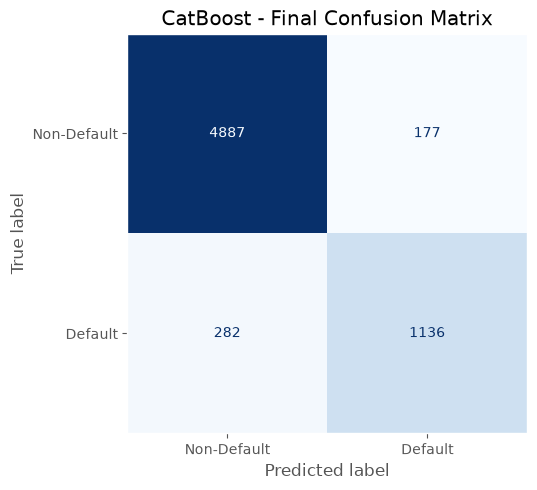

              precision    recall  f1-score   support

 Non-Default       0.95      0.97      0.96      5064
     Default       0.87      0.80      0.83      1418

    accuracy                           0.93      6482
   macro avg       0.91      0.88      0.89      6482
weighted avg       0.93      0.93      0.93      6482



In [277]:
final_model = clone(model_pipelines[best_model_name])
final_model.fit(X_train, y_train)
test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)
final_metrics = calculate_metrics(y_test, test_predictions, test_probabilities)

final_results = pd.DataFrame([{'Model': best_model_name, 'Threshold': best_threshold, **final_metrics}])

display(final_results.round(4))

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    ax=ax,
    cmap='Blues',
    colorbar=False,
    display_labels=['Non-Default', 'Default']
)

ax.set_title(f'{best_model_name} - Final Confusion Matrix')
ax.grid(False)

plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    test_predictions,
    target_names=['Non-Default', 'Default'],
    zero_division=0
))

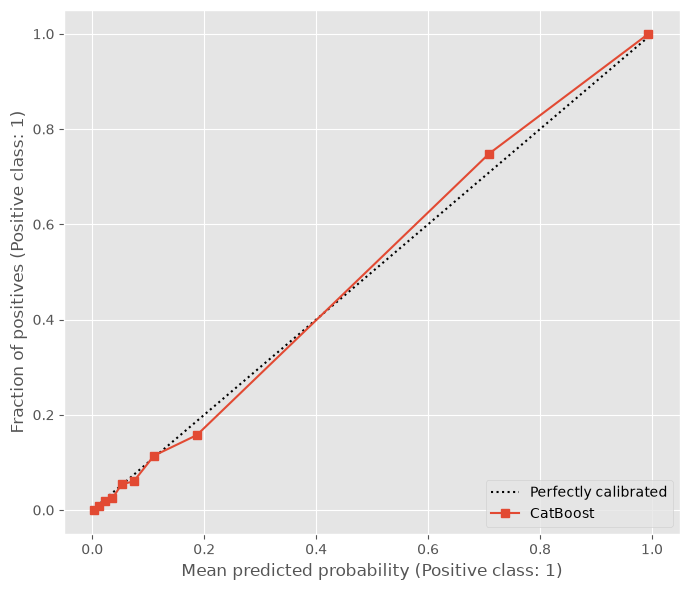

Selected model test Brier score: 0.0495


In [289]:
fig, axes = plt.subplots(figsize=(7,6))
CalibrationDisplay.from_predictions(y_test, test_probabilities, ax=axes, n_bins=10, strategy='quantile', name = 'CatBoost')
ax.set_title("Probability calibration — selected model, test set")
plt.tight_layout()
plt.show()


print(f"Selected model test Brier score: "
      f"{brier_score_loss(y_test, test_probabilities):.4f}")

,Model,Brier Score
0,Original CatBoost,0.0590
1,Calibrated CatBoost,0.0594


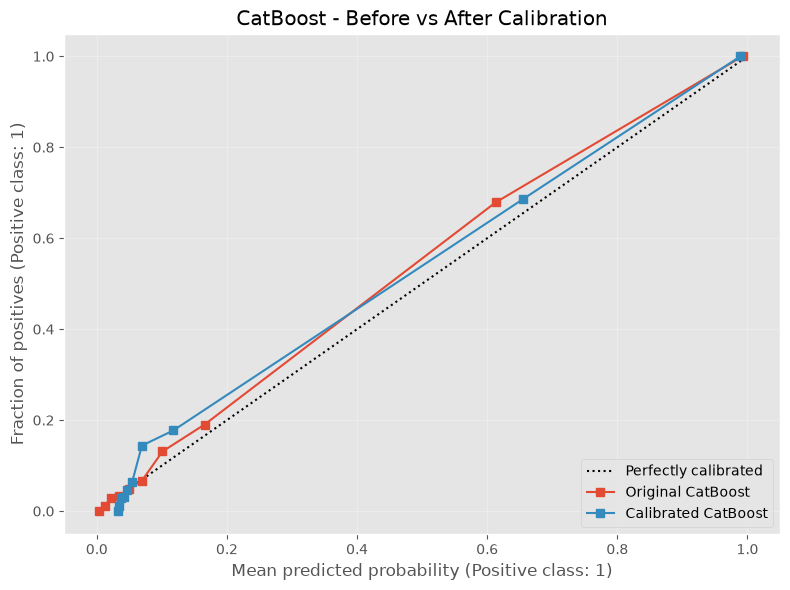

In [292]:
calibrated_model = CalibratedClassifierCV(final_model, method='sigmoid', cv=5, n_jobs=-1)
calibrated_model.fit(X_tune_train, y_tune_train)
calibrated_valid_probabilities = calibrated_model.predict_proba(X_valid)[:, 1]
calibration_results = pd.DataFrame({
    'Model': [
        'Original CatBoost',
        'Calibrated CatBoost'
    ],
    'Brier Score': [
        brier_score_loss(y_valid, valid_probabilities),
        brier_score_loss(y_valid, calibrated_valid_probabilities)
    ]
})

display(calibration_results.round(4))

fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_valid,
    valid_probabilities,
    n_bins=10,
    strategy='quantile',
    name='Original CatBoost',
    ax=ax
)

CalibrationDisplay.from_predictions(
    y_valid,
    calibrated_valid_probabilities,
    n_bins=10,
    strategy='quantile',
    name='Calibrated CatBoost',
    ax=ax
)

ax.set_title('CatBoost - Before vs After Calibration')

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# SHAP

In [302]:
shap_preprocessor = final_model.named_steps['preprocessor']
shap_model = final_model.named_steps['model']
X_test_transformed = shap_preprocessor.transform(X_test)
feature_names = final_model.named_steps['preprocessor'].get_feature_names_out()

X_test_transformed = pd.DataFrame(X_test_transformed, index=X_test.index, columns=feature_names)
X_test_transformed

,numeric__person_age,numeric__person_income,numeric__person_emp_length,numeric__loan_amnt,numeric__loan_int_rate,numeric__loan_percent_income,numeric__cb_person_cred_hist_length,categorical__person_home_ownership_MORTGAGE,categorical__person_home_ownership_OTHER,categorical__person_home_ownership_OWN,...,categorical__loan_intent_VENTURE,categorical__loan_grade_A,categorical__loan_grade_B,categorical__loan_grade_C,categorical__loan_grade_D,categorical__loan_grade_E,categorical__loan_grade_F,categorical__loan_grade_G,categorical__cb_person_default_on_file_N,categorical__cb_person_default_on_file_Y
16636,22.0,42996.0,3.0,4800.0,11.03,0.11,4.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
26980,31.0,108000.0,11.0,35000.0,13.49,0.32,10.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
19849,30.0,42000.0,5.0,11000.0,10.36,0.26,10.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
24183,31.0,45000.0,4.0,10000.0,10.65,0.22,5.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
25071,34.0,30412.0,4.0,12000.0,10.38,0.39,5.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7643,24.0,24000.0,0.0,6825.0,5.42,0.28,4.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
10316,24.0,60516.0,8.0,18000.0,11.26,0.30,4.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2334,23.0,31577.0,6.0,2500.0,6.92,0.08,4.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
28291,28.0,50000.0,4.0,7200.0,10.99,0.14,9.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


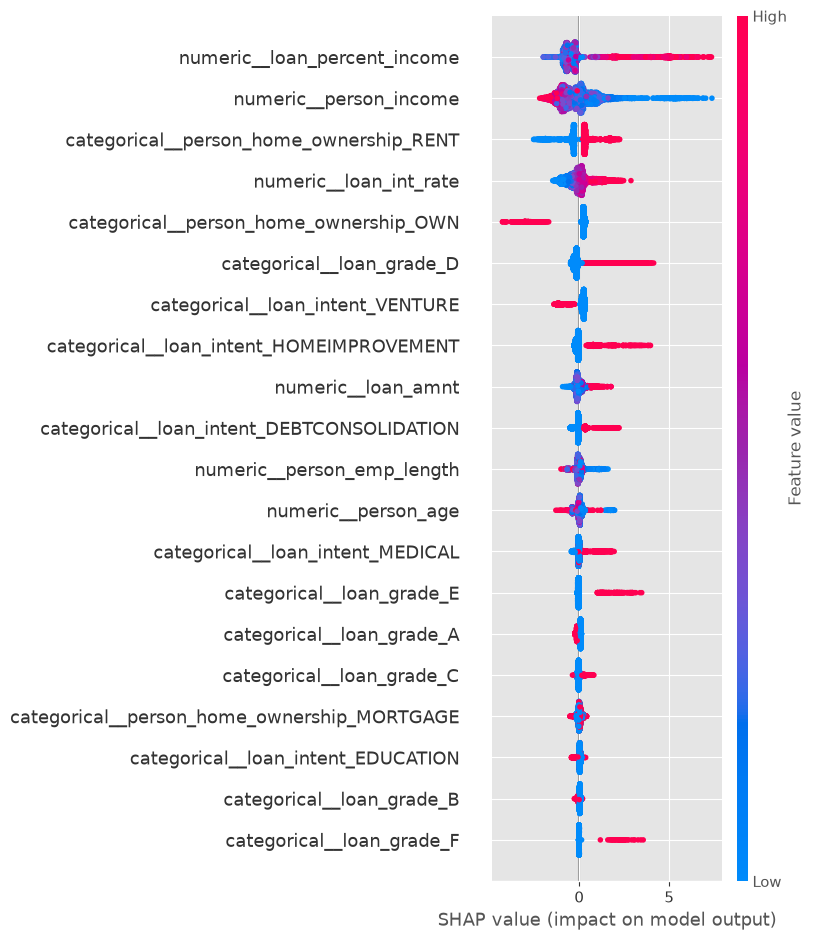

In [305]:
explainer = shap.TreeExplainer(shap_model)
shap_values = explainer(X_test_transformed)
shap.summary_plot(shap_values, X_test_transformed)

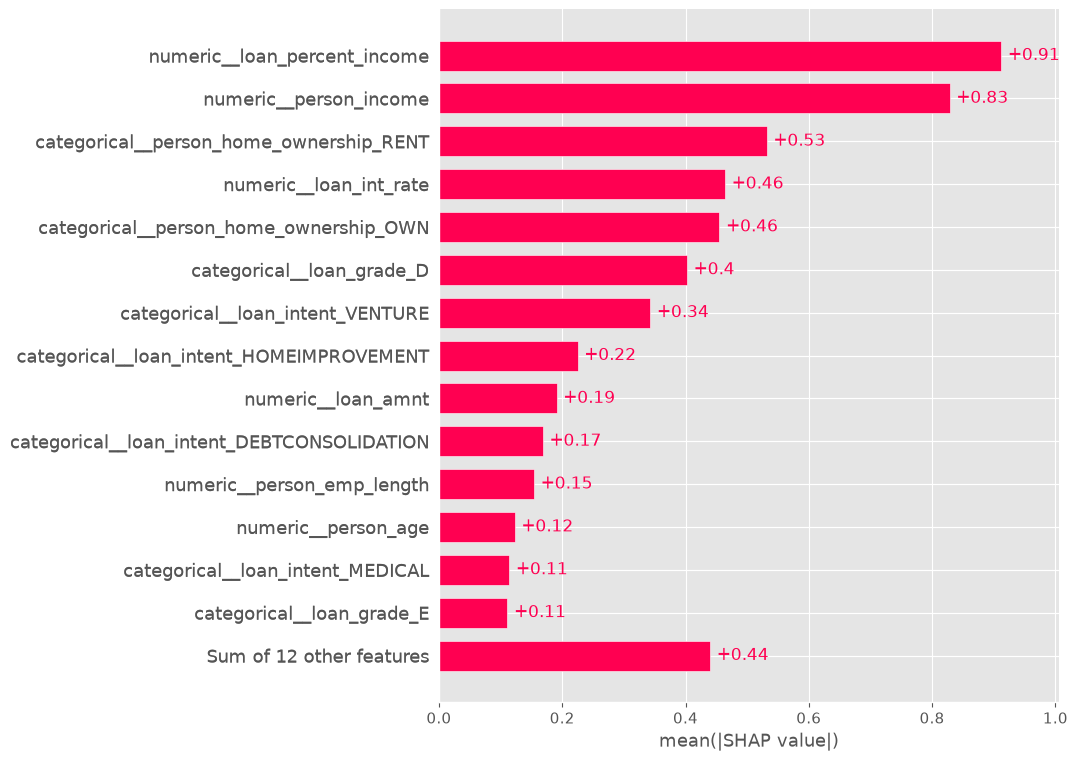

In [306]:
shap.plots.bar(shap_values, max_display=15)

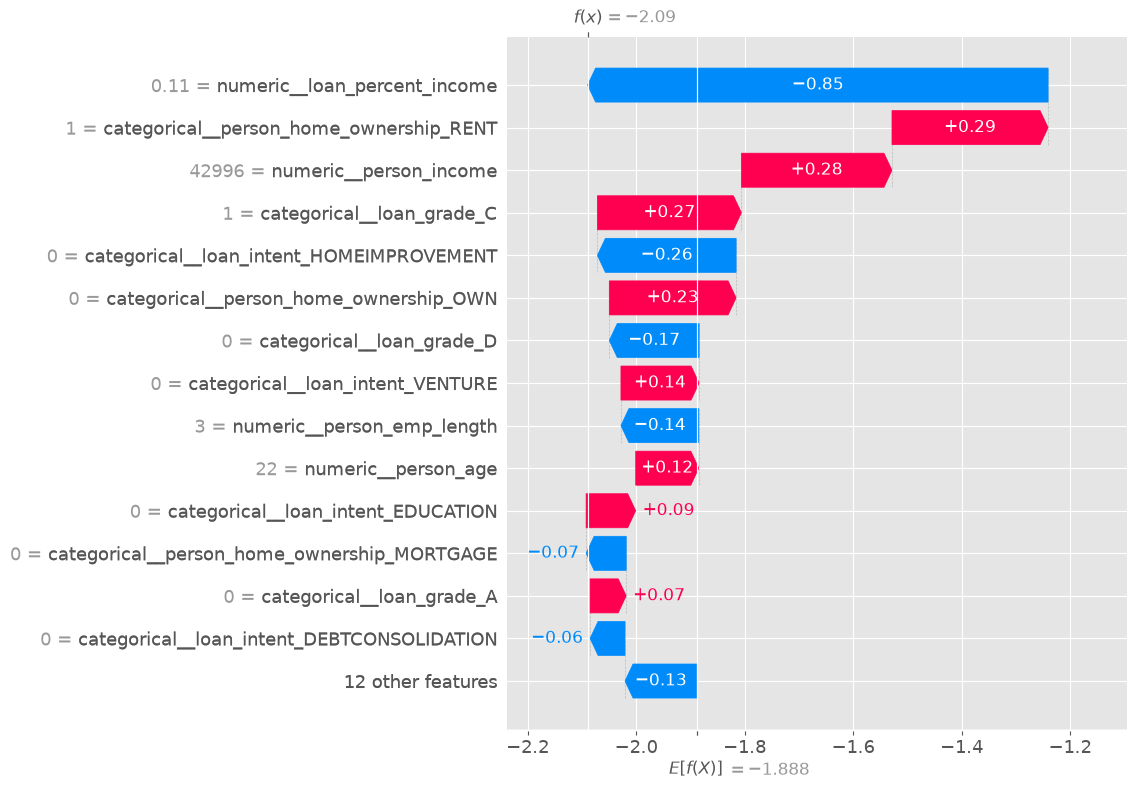

In [307]:
shap.plots.waterfall(shap_values[0], max_display=15)

# Error Analysis

In [309]:
error_analysis = X_test.copy()
error_analysis['actual'] = y_test
error_analysis['prediction'] = test_predictions
error_analysis['default_probability'] = test_probabilities
error_analysis['error_type'] = np.where((error_analysis['actual'] == error_analysis['prediction']),'Correct', 
                                        np.where((error_analysis['actual'] == 1),'False Negative', 'False Positive'))

display(error_analysis['error_type'].value_counts())

error_type
Correct           6023
False Negative     282
False Positive     177
Name: count, dtype: int64

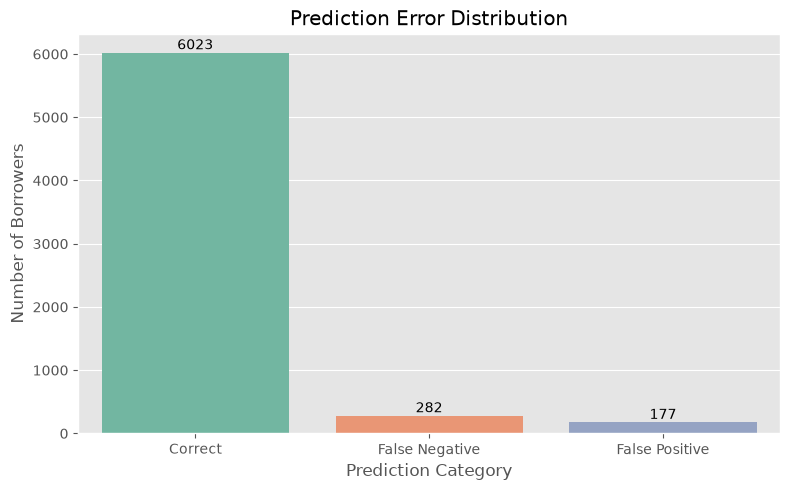

In [314]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(data=error_analysis, x='error_type', hue='error_type', palette='Set2')
for container in ax.containers:
    ax.bar_label(container)
plt.title('Prediction Error Distribution')
plt.xlabel('Prediction Category')
plt.ylabel('Number of Borrowers')

plt.tight_layout()
plt.show()

In [321]:
false_positives = error_analysis[error_analysis['error_type'] == 'False Positive']
print("Number of False Positives:", len(false_positives))
display(false_positives.sort_values('default_probability', ascending=False).head(10))

Number of False Positives: 177


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,prediction,default_probability,error_type
12437,25,44004,RENT,9.0,MEDICAL,E,12000,16.45,0.27,Y,4,0,1,0.964513,False Positive
1597,24,39000,RENT,8.0,MEDICAL,D,1500,15.62,0.04,Y,3,0,1,0.930353,False Positive
24235,35,46000,RENT,3.0,MEDICAL,E,10000,17.14,0.22,N,5,0,1,0.813245,False Positive
19139,30,31200,RENT,7.0,MEDICAL,D,2400,16.49,0.08,Y,6,0,1,0.747158,False Positive
20776,29,42000,RENT,3.0,MEDICAL,D,5000,15.99,0.12,Y,6,0,1,0.709255,False Positive
26782,27,112921,MORTGAGE,11.0,HOMEIMPROVEMENT,E,19000,16.35,0.17,N,10,0,1,0.700586,False Positive
3878,25,39000,MORTGAGE,9.0,HOMEIMPROVEMENT,C,3000,13.99,0.08,Y,3,0,1,0.698652,False Positive
16340,25,39000,MORTGAGE,9.0,DEBTCONSOLIDATION,C,3000,13.99,0.08,N,2,0,1,0.675872,False Positive
5148,25,44000,MORTGAGE,2.0,VENTURE,D,12000,14.54,0.27,N,2,0,1,0.650260,False Positive
22295,30,54000,MORTGAGE,12.0,MEDICAL,C,15000,14.72,0.28,Y,9,0,1,0.644140,False Positive


In [322]:
false_positives = error_analysis[error_analysis['error_type'] == 'False Negative']
print("Number of False Negative:", len(false_positives))
display(false_positives.sort_values('default_probability', ascending=False).head(10))

Number of False Negative: 282


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,prediction,default_probability,error_type
4734,24,30000,RENT,6.0,DEBTCONSOLIDATION,B,5000,12.69,0.17,N,4,1,0,0.257452,False Negative
4354,22,19800,RENT,NaN,DEBTCONSOLIDATION,B,4800,10.99,0.24,N,2,1,0,0.255709,False Negative
748,23,61200,RENT,4.0,MEDICAL,B,20000,11.14,0.28,N,2,1,0,0.253064,False Negative
6311,25,29000,RENT,0.0,MEDICAL,C,6000,13.49,0.21,N,3,1,0,0.252936,False Negative
13340,23,74000,RENT,7.0,VENTURE,D,2800,15.21,0.04,Y,2,1,0,0.252241,False Negative
14739,26,101000,MORTGAGE,10.0,VENTURE,F,25000,17.46,0.25,N,4,1,0,0.251001,False Negative
12921,25,73000,MORTGAGE,8.0,PERSONAL,D,20000,13.12,0.27,Y,4,1,0,0.250757,False Negative
6735,23,44000,MORTGAGE,7.0,PERSONAL,A,8500,7.14,0.19,N,3,1,0,0.249582,False Negative
22536,27,49500,MORTGAGE,7.0,VENTURE,C,4750,15.27,0.10,N,7,1,0,0.248564,False Negative
11824,23,59500,MORTGAGE,1.0,MEDICAL,B,20000,11.83,0.29,N,4,1,0,0.246048,False Negative


In [324]:
error_comparison = error_analysis.groupby('error_type')[[
    'person_age',
        'person_income',
        'person_emp_length',
        'loan_amnt',
        'loan_int_rate',
        'loan_percent_income',
        'cb_person_cred_hist_length'
]].median()

In [325]:
error_comparison

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
error_type,,,,,,,
Correct,26.0,56000.0,4.0,8000.0,10.95,0.15,4.0
False Negative,26.0,55161.5,4.0,7000.0,11.49,0.13,4.0
False Positive,26.0,43200.0,5.0,7800.0,14.22,0.17,4.0


In [329]:
artifacts_dir = Path('artifacts')
artifacts_dir.mkdir(parents=True, exist_ok=True)

In [333]:
model_path = artifacts_dir / 'credit_risk_catboost.joblib'
joblib.dump(final_model, model_path)
print(f"Model saved successfully: {model_path}")

Model saved successfully: artifacts/credit_risk_catboost.joblib


In [338]:
metadata = {
    'model_name': best_model_name,
    'model_type': 'CatBoostClassifier',
    'target': 'loan_status',
    'target_mapping': {
        '0': 'Non-Default',
        '1': 'Default'
    },
    'classification_threshold': float(best_threshold),
    'threshold_optimization_metric': 'F1',
    'threshold_selection_split': 'Validation',
    'model_selection_metric': 'Average Precision',
    'features': X_train.columns.tolist(),
    'training_rows': len(X_train),
    'random_state': RANDOM_STATE,
    'sklearn_version': sklearn.__version__,
    'catboost_version': catboost.__version__
}

In [341]:
metadata_path = artifacts_dir / 'model_metadata.json'

with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=4)
print("Model metadata saved successfully.")

Model metadata saved successfully.
